# Beyond RECIST: mathematical modeling and Bayesian inference reveals immune parameters predict site specific response in metastatic breast cancer

In [134]:
#load packages
using DifferentialEquations
using Turing
using MCMCChains
using StatsPlots
using Distributions
using NonlinearSolve
using DecisionTree
using ScikitLearn.CrossValidation: cross_val_score
using Symbolics
using DataFrames
using KernelDensity
using Plots; pyplot()
using Random
using JLD
using FileIO
using CSV

In [2]:
#define colors for plotting
logocolors = Colors.JULIA_LOGO_COLORS
color_vector_increasing = cgrad(:hot, 36, categorical = true)
color_vector_decreasing = cgrad(:winter, 32, categorical = true, rev = true)
color_vector_other = palette(:tab10)
color_vector_patient = cgrad(:lightrainbow, 20, categorical = true, rev = false)
color1 = RGBA(113/255,46/255,103/255,1)
color2 = RGBA(38/255,117/255,146/255,1)
color3 = RGBA(95/255,177/255,42/255,1)
color4 = RGBA(199/255,200/255,0/255,1)
color5 = RGBA(255/255,121/255,23/255,1)
color6 = RGBA(226/255,58/255,52/255,1)
color_vector_paper = [color6, color6, color6, color6, color6, color6, color6, color6, color6, color6, color2, color2, color2, color2, color2, color2, color2, color2, color2, color2]
color_vector = [color1, color2, color3, color4, color5, color6]

## Select parameters to fit and define mathematical model

In [3]:
#define model parameters
α₂ = 5.0*(10.0^2.0) #MDSCs production rate
α₃ = (10.0^8.0) #MDSCs expansion coefficient 
ζ₂ = 0.2 #MDSCs death rate

α₁ = 10.0^(-1.0) #tumor growth rate
η = 10.0^7.0 #tumor maximum size
β₁ = 6.0*(10.0^(-4.0)) #tumor cells kill rate by NK cells
β₂ = 7.0*(10.0^(-4.0)) #tumor cells kill rate by T cells
ζ₁ = 0.0 #tumor cell death rate

α₄ = 5.0*(10.0^1.0) #NK cells production rate
α₅ = 2.5*(10.0^(-2.0)) #NK cells expansion coefficient
β₃ = 4*(10.0^(-5.0)) #NK cells inactivation rate by MDSCs
ζ₃ = 4.12*(10.0^(-2.0)) #NK cells death rate

α₆ = 4.0*(10.0^(-3.0)) #CTL stimulation as a result of tumor-NK cell interaction
α₇ = 10.0^(-1.0) #CTL expansion coefficient 
β₄ = (10.0^(-4.0)) #CTL inactivation rate by MDSCs
ζ₄ = 2.0*(10.0^(-2.0)) #CTL death rate

γ₁ = (10.0^(10.0)) #steepness coefficient of MDSC production curve
γ₂ = 2.02*(10.0^(7.0)) #steepness coefficient of NK production curve
γ₃ = 2.02*(10.0^(7.0)) #steepness coefficient of CTL production curve

2.02e7

In [4]:
#choose parameters to fit and define prior distributions

#parameters = [β₁, β₂, β₃, β₄, α₆]
#parameters_symbols = [:β₁, :β₂, :β₃, :β₄, :α₆]
#parameter_priors = [truncated(Normal(6.0*(10.0^(-4.0)),10.0^(-4.0)),0.0,10.0^(-2.0)), truncated(Normal(7.0*(10.0^(-4.0)),10.0^(-4.0)),0.0,10.0^(-2.0)), truncated(Normal(4.0*10.0^(-5.0),10.0^(-4.0)),0.0,10.0^(-2.0)), truncated(Normal((10.0^(-4.0)),10.0^(-4.0)),0.0,10.0^(-2.0)), truncated(Normal(4.0*(10.0^(-3.0)),(10.0^(-2.0))),0.0,10.0^(-1.0)), InverseGamma(2, 3)]

parameters = [β₃, β₄, α₆]
parameters_symbols = [:β₃, :β₄, :α₆]
parameter_priors = [truncated(Normal(4.0*10.0^(-5.0),10.0^(-4.0)),0.0,10.0^(-2.0)), truncated(Normal((10.0^(-4.0)),10.0^(-4.0)),0.0,10.0^(-2.0)), truncated(Normal(4.0*(10.0^(-3.0)),(10.0^(-2.0))),0.0,10.0^(-1.0)), InverseGamma(2, 3)]

number_of_parameters = length(parameters_symbols)

3

In [5]:
#define model
function ode_system(du,u,p,t)
    T,MDSC,NK,CTL = u
    #β₁, β₂, β₃, β₄, α₆ = p
    β₃, β₄, α₆ = p
    
# Cancer cells (tumor)
    du[1] = dT = α₁*T*log(max(η/T,1)) - β₁*T*NK - β₂*T*CTL - ζ₁*T
 # MDSCs 
    du[2] = dMDSC = α₂ + α₃*T/(γ₁+(T)) - ζ₂*MDSC 
 # NK cells
    du[3] = dNK = α₄ + α₅*(T^2)/(γ₂+(T^2)) - β₃*MDSC*NK - ζ₃*NK 
 # CTL cells
    du[4] = dCTL = α₆*T*NK + α₇*(T^2)/(γ₃+(T^2)) - β₄*MDSC*CTL - ζ₄*CTL
end

ode_system (generic function with 1 method)

In [6]:
#define powerset function
function powerset(x::Vector{T}) where T
    result = Vector{T}[[]]
    for elem in x, j in eachindex(result)
        push!(result, [result[j] ; elem])
    end
    result
end

powerset (generic function with 1 method)

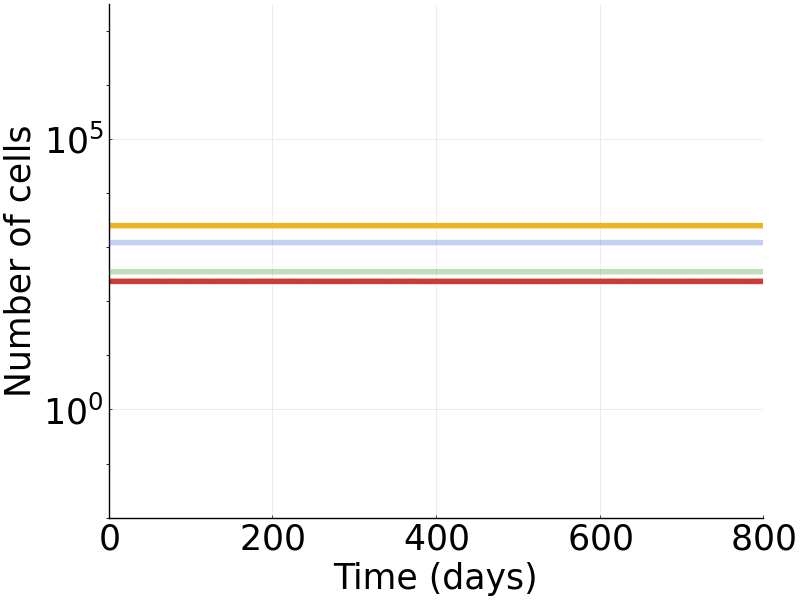

In [7]:
#set numerical solution algorithm
alg = Tsit5()

#define condition for simulation to end
function condition(u,t,integrator) 
  u[1] < 0.0 || u[2] < 0.0 || u[3] < 0.0 || u[4] < 0.0
end

floor_event = DiscreteCallback(condition, terminate!)

#simulate model at steady state
α₂ = 5.0*(10.0^2.0) #MDSCs production rate
α₃ = (10.0^8.0) #MDSCs expansion coefficient 
ζ₂ = 0.2 #MDSCs death rate

α₁ = 10.0^(-1.0) #tumor growth rate
η = 10.0^7.0 #tumor maximum size
β₁ = 6.0*(10.0^(-4.0)) #tumor cells kill rate by NK cells
β₂ = 7.0*(10.0^(-4.0)) #tumor cells kill rate by T cells
ζ₁ = 0.0 #tumor cell death rate

α₄ = 5.0*(10.0^1.0) #NK cells production rate
α₅ = 2.5*(10.0^(-2.0)) #NK cells expansion coefficient
β₃ = 4*(10.0^(-5.0)) #NK cells inactivation rate by MDSCs
ζ₃ = 4.12*(10.0^(-2.0)) #NK cells death rate

α₆ = 4.0*(10.0^(-3.0)) #CTL stimulation as a result of tumor-NK cell interaction
α₇ = 10.0^(-1.0) #CTL expansion coefficient 
β₄ = (10.0^(-4.0)) #CTL inactivation rate by MDSCs
ζ₄ = 2.0*(10.0^(-2.0)) #CTL death rate

γ₁ = (10.0^(10.0)) #steepness coefficient of MDSC production curve
γ₂ = 2.02*(10.0^(7.0)) #steepness coefficient of NK production curve
γ₃ = 2.02*(10.0^(7.0)) #steepness coefficient of CTL production curve

p = parameters

tspan = (0.0,800.0)
u0 = [234.52607557161835;2511.7148454521493;352.93622128903235;1219.5854955705156]

prob1 = ODEProblem(ode_system,u0,tspan,p)
sol = solve(prob1,alg,saveat=0.1,callback=floor_event)
plot(sol, lw = 4, yaxis=:log,size =(1600/2,600), font = "Ariel", ylims = (0.01,10^7.5), color = [logocolors.red "goldenrod2" logocolors.green logocolors.blue], alpha = [1 1 0.3 0.3], legend = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Number of cells",yguidefontsize=25,title = "",titlefontsize=25)

## Load and plot data

In [8]:
#load data
data_raw = CSV.read("data_all.csv", DataFrame; delim = ',', header = false, ignoreemptyrows=true)
data_location_raw = CSV.read("data_location.csv", DataFrame; delim = ',', header = false, ignoreemptyrows=true)
data_location_general_raw = CSV.read("data_location_general.csv", DataFrame; delim = ',', header = false, ignoreemptyrows=true)
patient_classification_raw = CSV.read("data_response.csv", DataFrame; delim = ',', header = false, ignoreemptyrows=true)
IMC_raw = CSV.read("IMC.csv", DataFrame; delim = ',', header = false, ignoreemptyrows=true)
patient_classification = [1 4 ; 5 6 ; 7 9; 10 11 ; 12 15 ; 16 16 ; 17 18 ; 19 21 ; 22 23 ; 24 26 ; 27 30 ; 31 34 ; 35 37 ; 38 38 ; 39 41 ; 42 44 ; 45 47 ; 48 51 ; 52 54 ; 55 55]

data_array = Array(data_raw)
data_location_array = Array(data_location_raw)
data_location_general_array = Array(data_location_general_raw)
patient_classification_array = Array(patient_classification_raw)
IMC_array = Array(IMC_raw)

vector_location = replace(data_location_general_array, "Liver" =>1, "Lung" =>2, "Lymph node" =>3, "Breast" =>4, "Chest" =>5, "Peritoneal/retroperitoneal " =>6, "Axillary mass" =>7, "Skin" =>8, "Adrenal" =>9, "Pleural" =>10, "Other" =>11)
vector_location_plot = replace(data_location_general_array, "Liver" =>1, "Lung" =>2, "Lymph node" =>3, "Breast" =>4, "Chest" =>5, "Peritoneal/retroperitoneal " =>6, "Axillary mass" =>6, "Adrenal" =>6, "Pleural" =>6, "Other" =>6, "Skin" =>6)

array_location = Array{Float64}(vector_location)
array_location_plot = Array{Float64}(vector_location_plot)

string_vector = ["Liver", "Lung", "Lymph node", "Breast", "Chest", "(Retro)peritoneal", "Axillary", "Skin", "Adrenal", "Pleural", "Other"]
string_vector_location = ["Liver", "Lung", "Lymph node", "Breast", "Chest", "Other"]

tumor_classification = []
number_of_data_points = []

for i = 1:Int(size(data_array,1)/2)
    tumor_time = collect(skipmissing(data_array[2*i-1,:]))
    tumor_size = collect(skipmissing(data_array[2*i,:]))
    for j = 2:convert(Int64, length(tumor_size))
        tumor_size[j] = (tumor_size[j]-tumor_size[1])./tumor_size[1]
    end
    tumor_size[1] = 0.0
    push!(number_of_data_points, length(tumor_size))
    
    if last(tumor_size) > 0
        push!(tumor_classification, "increasing")
    else
        push!(tumor_classification, "decreasing")
    end
end
number_of_tumors = Int(size(data_array,1)/2)

55

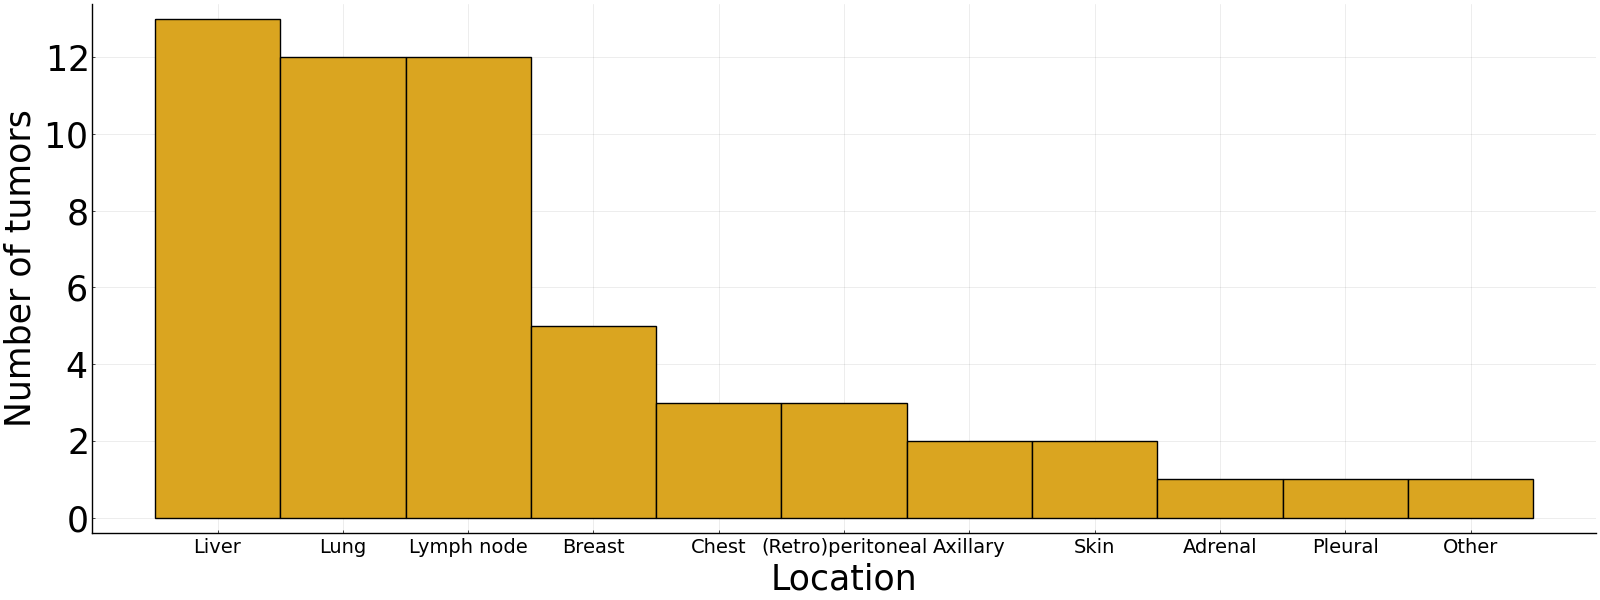

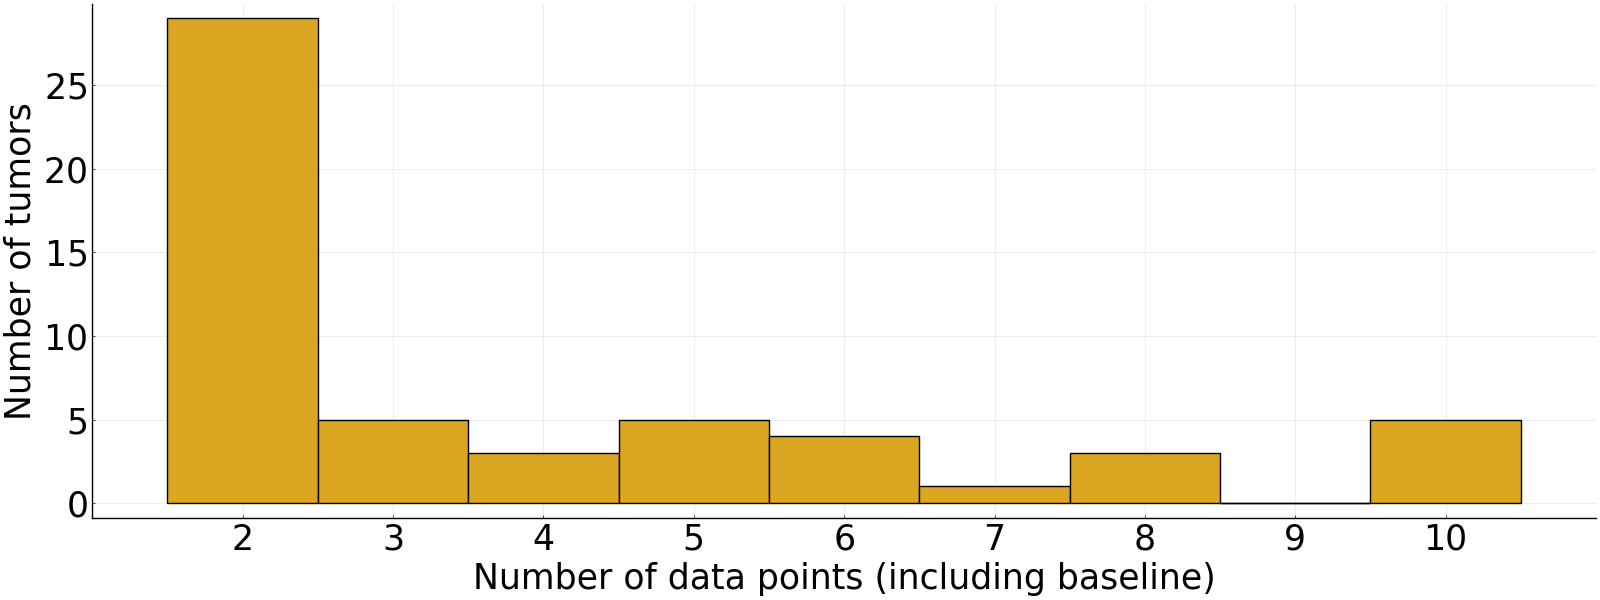

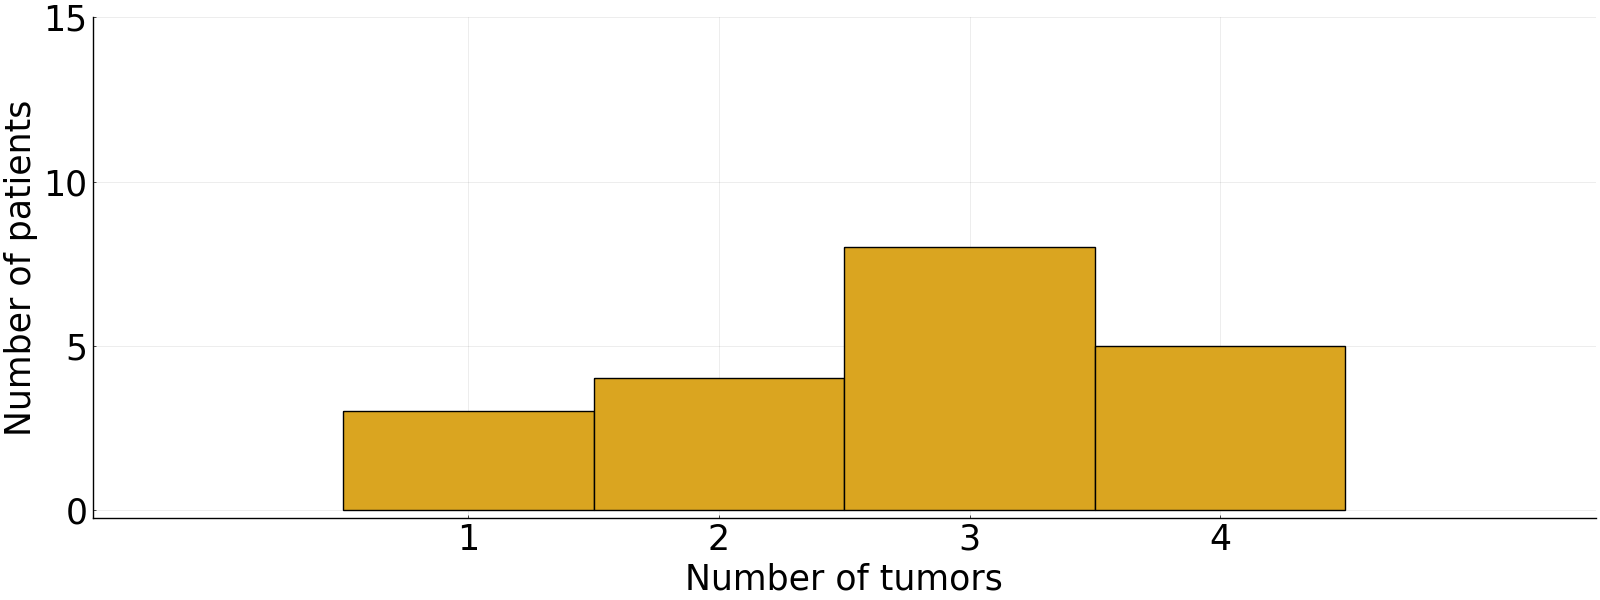

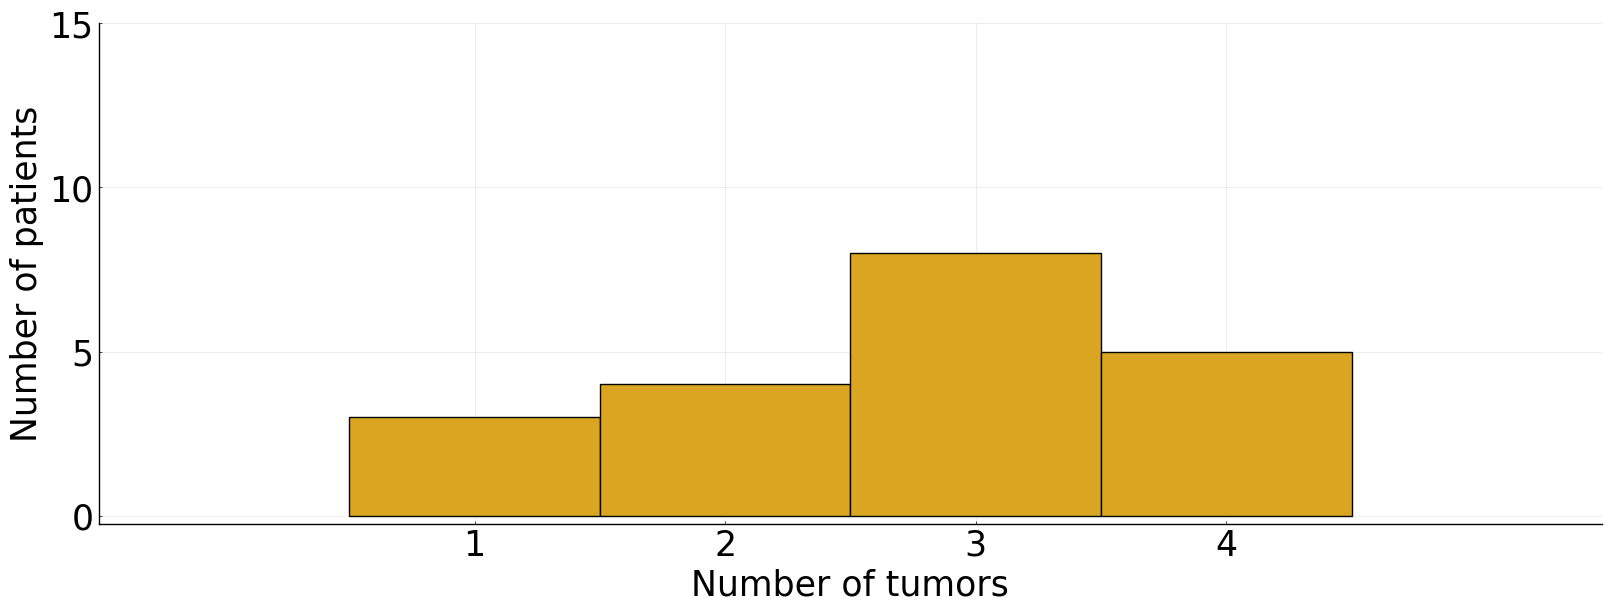

In [20]:
#basic statistics
display(histogram(array_location,nbins=11,markersize = 10, size =(1600,600), xlims = [0.5,12.5], xticks = (1.5:11.5,string_vector), font = "Ariel", color = "goldenrod", label = false, xrotation = 90, xtickfontsize=14,ytickfontsize=25,xlabel="Location",xguidefontsize=25,ylabel="Number of tumors",yguidefontsize=25,title = "",titlefontsize=25))
display(histogram(number_of_data_points, bins=9, size =(1600,600), xlims = [1.5,11.5], xticks = (2.5:10.5,2:10), font = "Ariel", color = "goldenrod", label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Number of data points (including baseline)",xguidefontsize=25,ylabel="Number of tumors",yguidefontsize=25,title = "",titlefontsize=25))
display(histogram(patient_classification[:,2]-patient_classification[:,1].+1,nbins=4,markersize = 10, size =(1600,600), xlims = [0,6], xticks = (1.5:4.5,1:4), yticks = (0:5:15,0:5:15), font = "Ariel", color = "goldenrod", label = false, xrotation = 90, xtickfontsize=25,ytickfontsize=25,xlabel="Number of tumors",xguidefontsize=25,ylabel="Number of patients",yguidefontsize=25,title = "",titlefontsize=25))

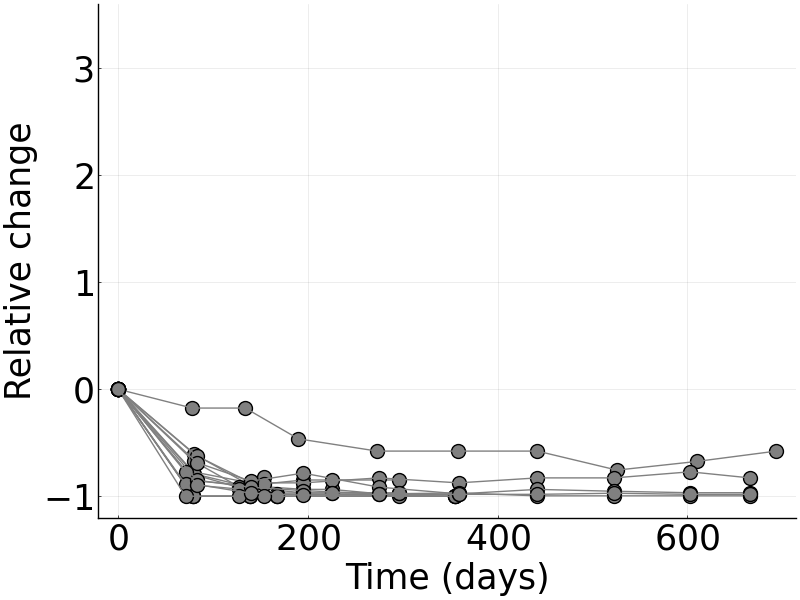

In [48]:
#plot responders
plot()

for m = 1:20
    if m in [1,11,13,14,18]
        for i = patient_classification[m,1]:patient_classification[m,2]
            tumor_time = collect(skipmissing(data_array[2*i-1,:]))
            tumor_size = collect(skipmissing(data_array[2*i,:]))
            for j = 2:convert(Int64, length(tumor_size))
                tumor_size[j] = (tumor_size[j]-tumor_size[1])./tumor_size[1]
            end
            tumor_size[1] = 0.0

            scatter!(tumor_time, tumor_size, markersize = 10, size =(1600/2,600), font = "Ariel", color = "gray", label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
            plot!(tumor_time, tumor_size, xticks = [0,200,400,600], yticks = (-1:3), ylims = [-1.2,3.6], size =(1600/2,600), font = "Ariel", color = "gray", label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
        end
    end
end
plot!()

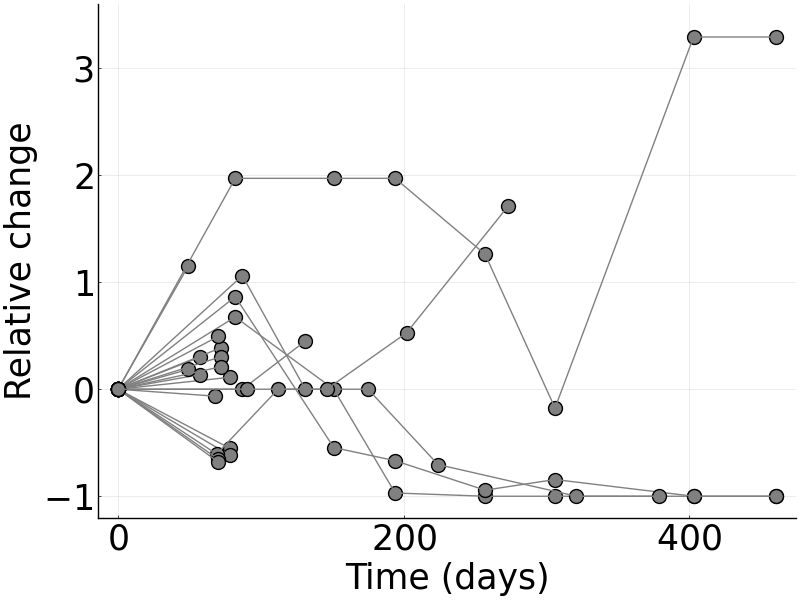

In [49]:
#plot stable disease
plot()

for m = 1:20
    if m ∈ [2,3,6,7,9,12,15,19,20]
        for i = patient_classification[m,1]:patient_classification[m,2]
            tumor_time = collect(skipmissing(data_array[2*i-1,:]))
            tumor_size = collect(skipmissing(data_array[2*i,:]))
            for j = 2:convert(Int64, length(tumor_size))
                tumor_size[j] = (tumor_size[j]-tumor_size[1])./tumor_size[1]
            end
            tumor_size[1] = 0.0

            scatter!(tumor_time, tumor_size, markersize = 10, size =(1600/2,600), font = "Ariel", color = "gray", label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
            plot!(tumor_time, tumor_size, yticks = (-1:3), xticks = [0,200,400], ylims = [-1.2,3.6], size =(1600/2,600), font = "Ariel", color = "gray", label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
        end
    end
end
plot!()

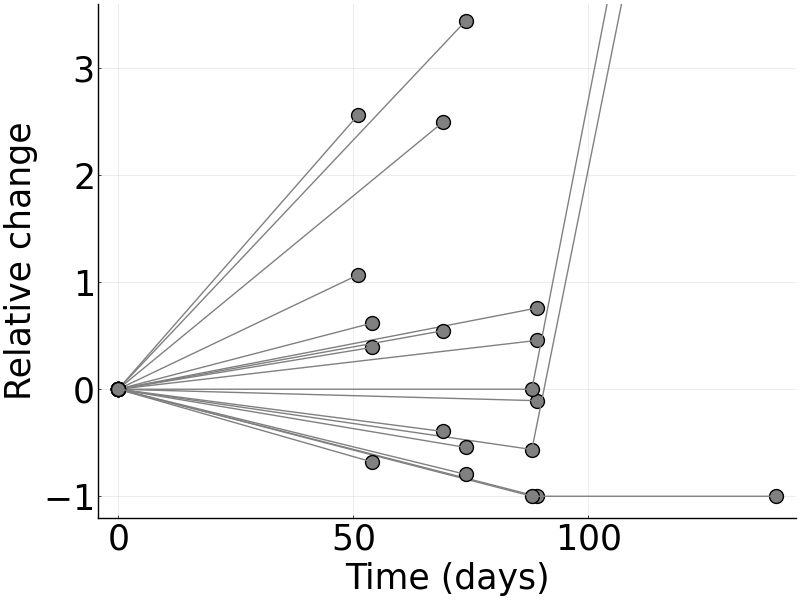

In [50]:
#plot progressive disease
plot()

for m = 1:20
    if m ∈ [4,5,8,10,16,17]
        for i = patient_classification[m,1]:patient_classification[m,2]
            tumor_time = collect(skipmissing(data_array[2*i-1,:]))
            tumor_size = collect(skipmissing(data_array[2*i,:]))
            for j = 2:convert(Int64, length(tumor_size))
                tumor_size[j] = (tumor_size[j]-tumor_size[1])./tumor_size[1]
            end
            tumor_size[1] = 0.0
            
            scatter!(tumor_time, tumor_size, markersize = 10, size =(1600/2,600), font = "Ariel", color = "gray", label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
            plot!(tumor_time, tumor_size, xticks = [0,50,100], yticks = (-1:3), ylims = [-1.2,3.6], size =(1600/2,600), font = "Ariel", color = "gray", label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
        end
    end
end
plot!()

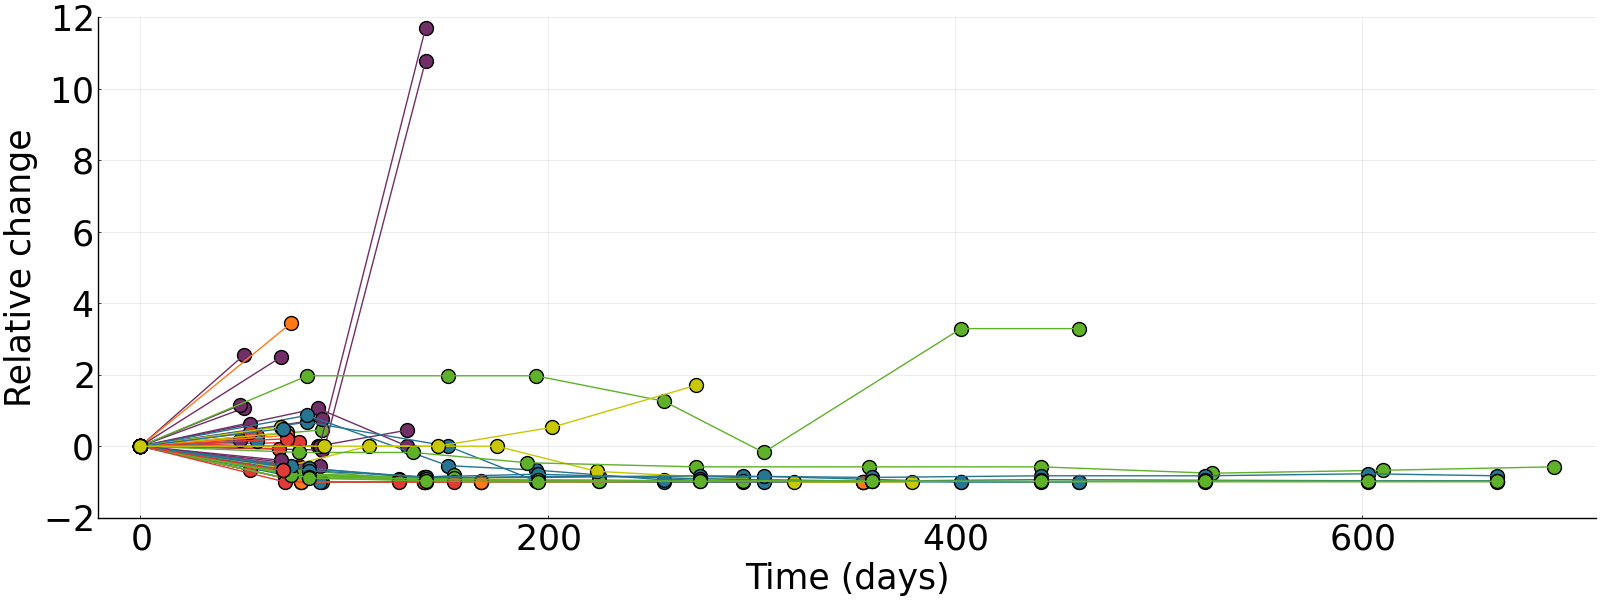

In [51]:
#plot 55 tumors by site
plot()

for i = 1:Int(size(data_array,1)/2)
    tumor_time = collect(skipmissing(data_array[2*i-1,:]))
    tumor_size = collect(skipmissing(data_array[2*i,:]))
    for j = 2:convert(Int64, length(tumor_size))
        tumor_size[j] = (tumor_size[j]-tumor_size[1])./tumor_size[1]
    end
    tumor_size[1] = 0.0
    
    scatter!(tumor_time, tumor_size, markersize = 10, size =(1600,600), font = "Ariel", color = color_vector[vector_location_plot[i]], label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
    plot!(tumor_time, tumor_size, ylims = [-2,12], size =(1600,600), font = "Ariel", color = color_vector[vector_location_plot[i]], label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
end
plot!()

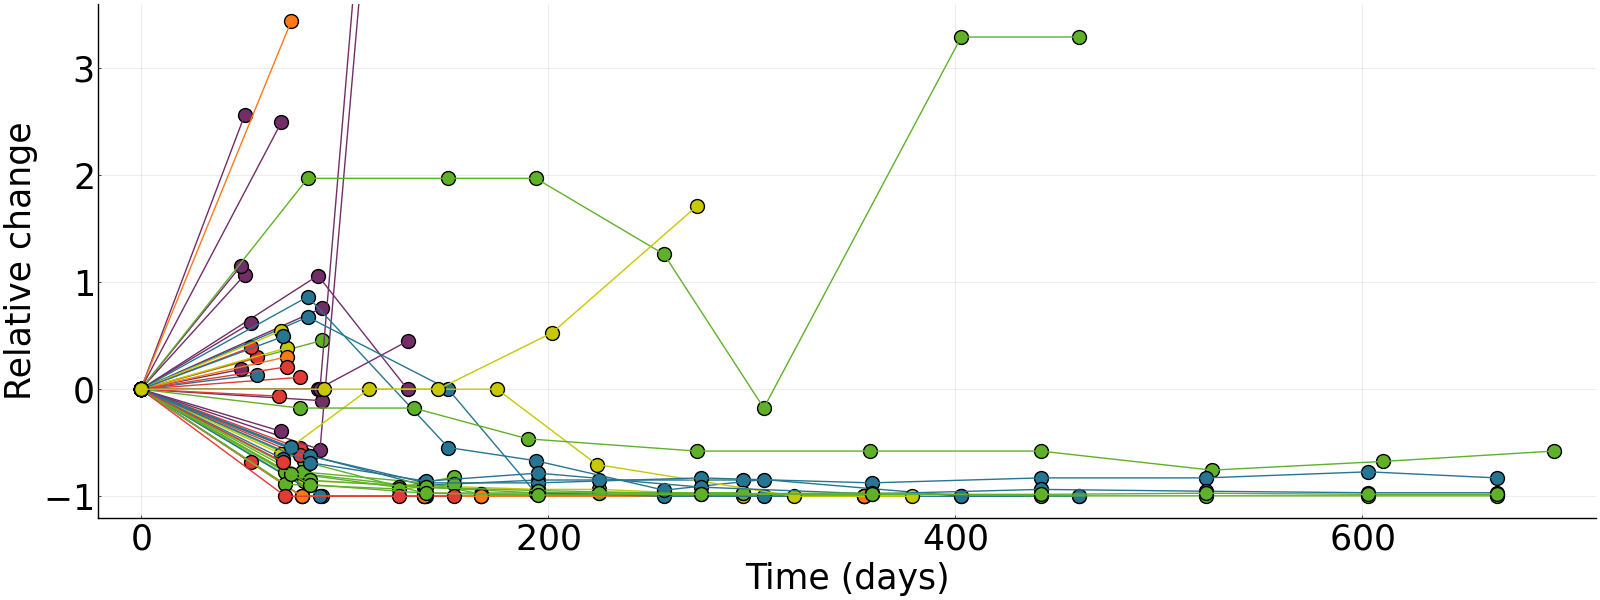

In [52]:
#plot 55 tumors by site (zoomed in)
plot()

for i = 1:Int(size(data_array,1)/2)
    tumor_time = collect(skipmissing(data_array[2*i-1,:]))
    tumor_size = collect(skipmissing(data_array[2*i,:]))
    for j = 2:convert(Int64, length(tumor_size))
        tumor_size[j] = (tumor_size[j]-tumor_size[1])./tumor_size[1]
    end
    tumor_size[1] = 0.0
    
    scatter!(tumor_time, tumor_size, markersize = 10, size =(1600,600), font = "Ariel", color = color_vector[vector_location_plot[i]], label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
    plot!(tumor_time, tumor_size, ylims = [-1.2,3.6], size =(1600,600), font = "Ariel", color = color_vector[vector_location_plot[i]], label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
end
plot!()

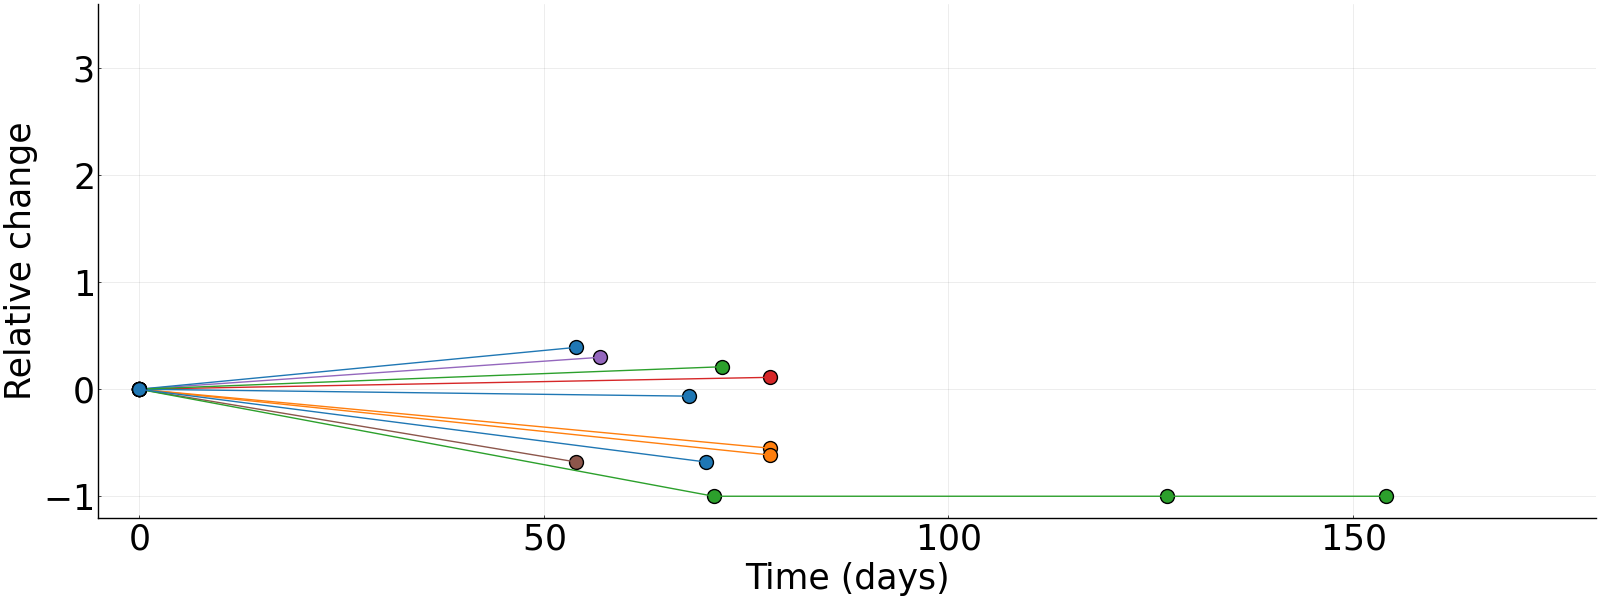

In [53]:
#plot "other" site category
plot()

for i = 1:Int(size(data_array,1)/2)
    tumor_time = collect(skipmissing(data_array[2*i-1,:]))
    tumor_size = collect(skipmissing(data_array[2*i,:]))
    for j = 2:convert(Int64, length(tumor_size))
        tumor_size[j] = (tumor_size[j]-tumor_size[1])./tumor_size[1]
    end
    tumor_size[1] = 0.0

    if vector_location[i] == 6
        scatter!(tumor_time, tumor_size, markersize = 10, size =(1600,600), font = "Ariel", color = color_vector_other[1], label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
        plot!(tumor_time, tumor_size, xlims = [-5,180], ylims = [-1.2,3.6], size =(1600,600), font = "Ariel", color = color_vector_other[1], label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
    end
    if vector_location[i] == 7 
        scatter!(tumor_time, tumor_size, markersize = 10, size =(1600,600), font = "Ariel", color = color_vector_other[2], label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
        plot!(tumor_time, tumor_size, xlims = [-5,180], ylims = [-1.2,3.6], size =(1600,600), font = "Ariel", color = color_vector_other[2], label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
    end
    if vector_location[i] == 8
        scatter!(tumor_time, tumor_size, markersize = 10, size =(1600,600), font = "Ariel", color = color_vector_other[3], label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
        plot!(tumor_time, tumor_size, xlims = [-5,180], ylims = [-1.2,3.6], size =(1600,600), font = "Ariel", color = color_vector_other[3], label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
    end
    if vector_location[i] == 9
        scatter!(tumor_time, tumor_size, markersize = 10, size =(1600,600), font = "Ariel", color = color_vector_other[4], label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
        plot!(tumor_time, tumor_size, xlims = [-5,180], ylims = [-1.2,3.6], size =(1600,600), font = "Ariel", color = color_vector_other[4], label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
    end
    if vector_location[i] == 10 
        scatter!(tumor_time, tumor_size, markersize = 10, size =(1600,600), font = "Ariel", color = color_vector_other[5], label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
        plot!(tumor_time, tumor_size, xlims = [-5,180], ylims = [-1.2,3.6], size =(1600,600), font = "Ariel", color = color_vector_other[5], label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
    end
    if vector_location[i] == 11 
        scatter!(tumor_time, tumor_size, markersize = 10, size =(1600,600), font = "Ariel", color = color_vector_other[6], label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
        plot!(tumor_time, tumor_size, xlims = [-5,180], ylims = [-1.2,3.6], size =(1600,600), font = "Ariel", color = color_vector_other[6], label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
    end
end
plot!()

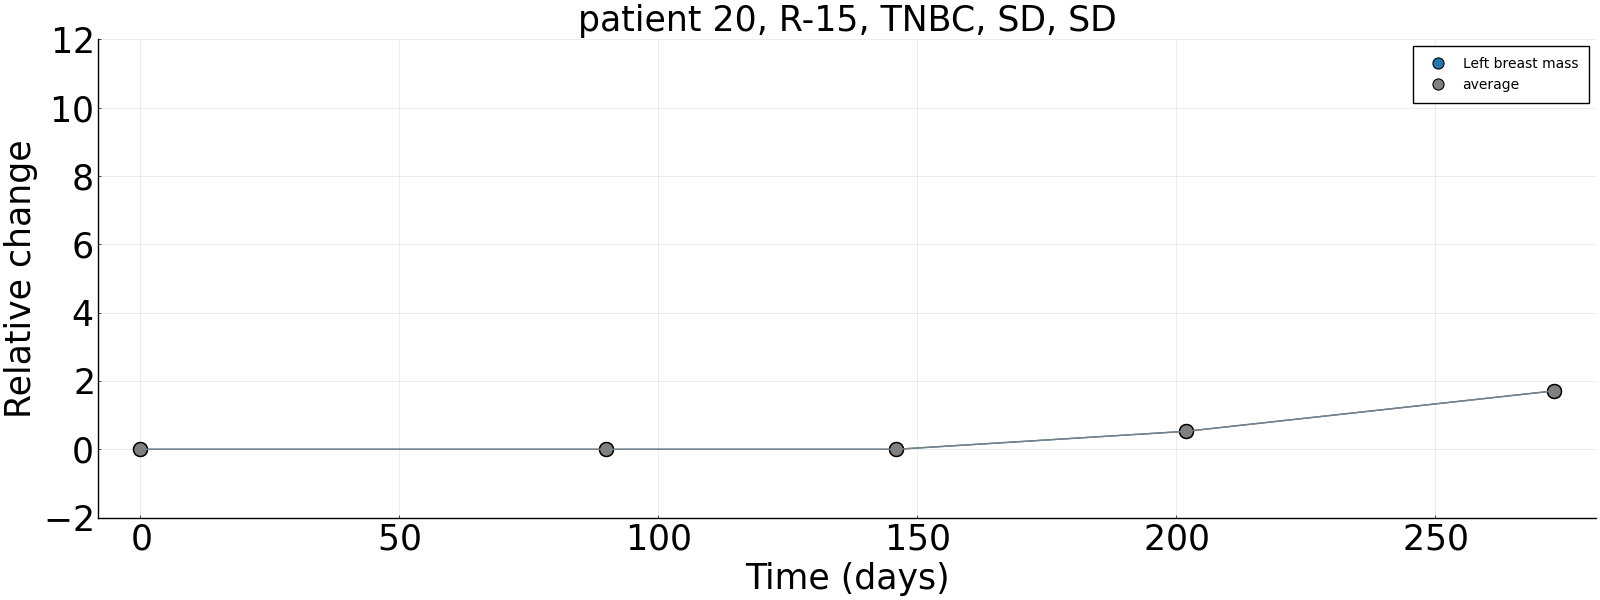

In [54]:
#plot tumors by patient
plot()
average_tumor_time = []
tumor_time = []

for m = 1:20
    if m ∉ [12]
        plot()
        m2 = 1
        average_tumor_time = []
        for i = patient_classification[m,1]:patient_classification[m,2]
            tumor_time = collect(skipmissing(data_array[2*i-1,:]))
            tumor_size = collect(skipmissing(data_array[2*i,:]))
            for j = 2:convert(Int64, length(tumor_size))
                tumor_size[j] = (tumor_size[j]-tumor_size[1])./tumor_size[1]
            end
            tumor_size[1] = 0.0

            average_tumor_time = append!(average_tumor_time, [tumor_size])

            scatter!(tumor_time, tumor_size, markersize = 10, size =(1600,600), font = "Ariel", color = palette(:tab10)[m2], label = data_location_array[patient_classification[m,1]+m2-1], legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)

            plot!(tumor_time, tumor_size, ylims = [-2,12], size =(1600,600), font = "Ariel", color = palette(:tab10)[m2], label = false, legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)

            m2 = m2+1
        end

        scatter!(tumor_time, mean(average_tumor_time), markersize = 10, size =(1600,600), font = "Ariel", color = "gray", label = "average", legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
        plot!(tumor_time, mean(average_tumor_time), ylims = [-2,12], size =(1600,600), font = "Ariel", color = "gray", label = false, legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)

        titletext1 = patient_classification_array[m,1]
        titletext2 = patient_classification_array[m,2]
        titletext3 = patient_classification_array[m,3]
        titletext4 = patient_classification_array[m,4]
        plot!(title = "patient $m, $titletext1, $titletext2, $titletext3, $titletext4")
    end
end
plot!()

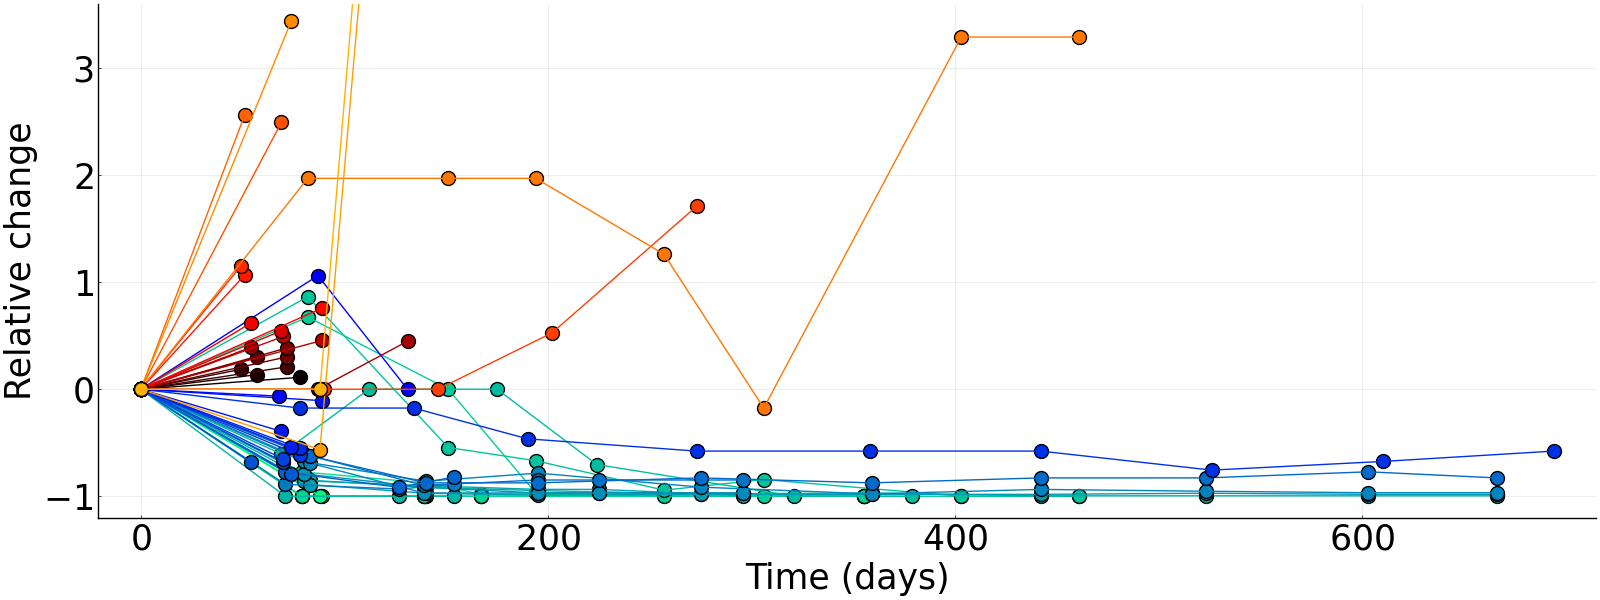

In [55]:
#plot tumors by increasing vs decreasing
tumor_increasing_vector = []
tumor_increasing_index = []
tumor_decreasing_vector = []
tumor_decreasing_index = []

for i = 1:Int(size(data_array,1)/2)
    tumor_time = collect(skipmissing(data_array[2*i-1,:]))
    tumor_size = collect(skipmissing(data_array[2*i,:]))
    for j = 2:convert(Int64, length(tumor_size))
        tumor_size[j] = (tumor_size[j]-tumor_size[1])./tumor_size[1]
    end
    tumor_size[1] = 0.0

    if last(tumor_size) > 0
        push!(tumor_increasing_vector, last(tumor_size))
        push!(tumor_increasing_index, i)
    else
        push!(tumor_decreasing_vector, last(tumor_size))
        push!(tumor_decreasing_index, i)
    end 
end

tumor_increasing = [tumor_increasing_index tumor_increasing_vector]
tumor_decreasing = [tumor_decreasing_index tumor_decreasing_vector]
tumor_increasing_sorted = tumor_increasing[sortperm(tumor_increasing[:, 2]), :]
tumor_decreasing_sorted = tumor_decreasing[sortperm(tumor_decreasing[:, 2]), :]

plot()

for i = 1:convert(Int64, length(tumor_decreasing_sorted)/2)
    k = convert(Int64, tumor_decreasing_sorted[i])
    tumor_time = collect(skipmissing(data_array[2*k-1,:]))
    tumor_size = collect(skipmissing(data_array[2*k,:]))
    for j = 2:convert(Int64, length(tumor_size))
        tumor_size[j] = (tumor_size[j]-tumor_size[1])./tumor_size[1]
    end
    tumor_size[1] = 0.0

    scatter!(tumor_time, tumor_size, markersize = 10, size =(1600,600), font = "Ariel", color = color_vector_decreasing[i], label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
    plot!(tumor_time, tumor_size, ylims = [-2,10], size =(1600,600), font = "Ariel", color = color_vector_decreasing[i], label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
end
plot!()

for i = 1:convert(Int64, length(tumor_increasing_sorted)/2)
    k = convert(Int64, tumor_increasing_sorted[i])
    tumor_time = collect(skipmissing(data_array[2*k-1,:]))
    tumor_size = collect(skipmissing(data_array[2*k,:]))
    for j = 2:convert(Int64, length(tumor_size))
        tumor_size[j] = (tumor_size[j]-tumor_size[1])./tumor_size[1]
    end
    tumor_size[1] = 0.0

    scatter!(tumor_time, tumor_size, markersize = 10, size =(1600,600), font = "Ariel", color = color_vector_increasing[i], label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
    plot!(tumor_time, tumor_size, ylims = [-1.2,3.6], size =(1600,600), font = "Ariel", color = color_vector_increasing[i], label = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
end
plot!()

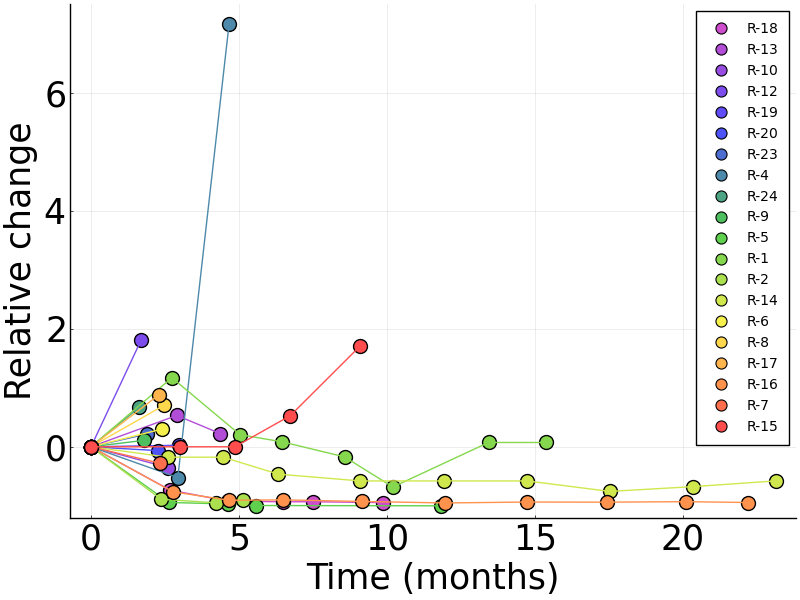

In [56]:
#plot average relative change by patient
plot()
average_tumor_time = []
tumor_time = []

for m = 1:20
    if m ∉ [12]
        m2 = 1
        average_tumor_time = []
        for i = patient_classification[m,1]:patient_classification[m,2]
            tumor_time = collect(skipmissing(data_array[2*i-1,:]))
            tumor_size = collect(skipmissing(data_array[2*i,:]))
            for j = 2:convert(Int64, length(tumor_size))
                tumor_size[j] = (tumor_size[j]-tumor_size[1])./tumor_size[1]
            end
            tumor_size[1] = 0.0
            
            average_tumor_time = append!(average_tumor_time, [tumor_size])
            m2 = m2+1
        end

        scatter!(tumor_time, mean(average_tumor_time), markersize = 10, size =(1600,600), font = "Ariel", color = color_vector_patient[m], label = patient_classification_array[m,1], legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
        plot!(tumor_time, mean(average_tumor_time), xticks = ([0,150,300,450,600],[0,5,10,15,20]), ylims = [-1.2,7.5], size =(800,600), font = "Ariel", color = color_vector_patient[m], label = false, legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (months)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)

    elseif m == 12
        tumor_time = [0,82,151,194,257,306,403,461]
        tumor_size = [0,1.169793341,0.204998873,0.083198169,-0.170529476,-0.680901777,0.072753906,0.072753906]
        
        scatter!(tumor_time, tumor_size, markersize = 10, size =(1600,600), font = "Ariel", color = color_vector_patient[m], label = patient_classification_array[m,1], legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
        plot!(tumor_time, tumor_size, xticks = ([0,150,300,450,600],[0,5,10,15,20]), ylims = [-1.2,7.5], size =(800,600), font = "Ariel", color = color_vector_patient[m], label = false, legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (months)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
    end
end
plot!()

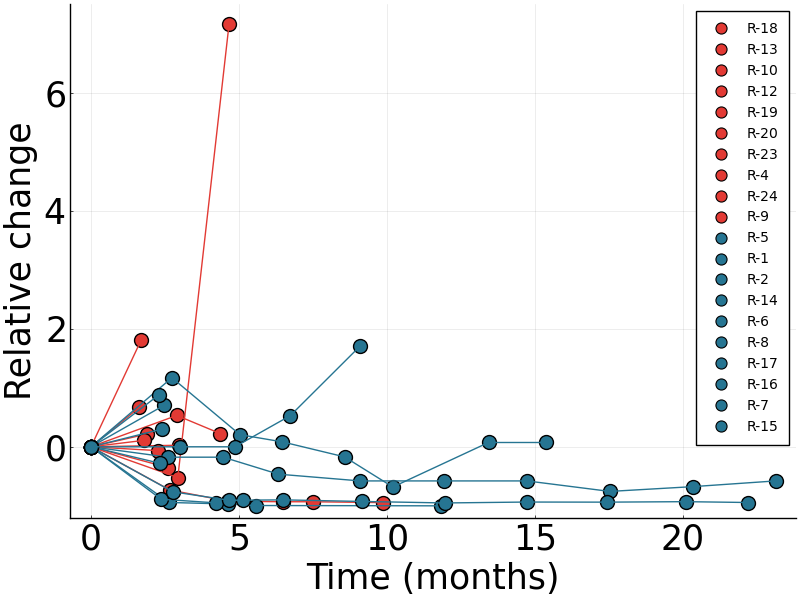

In [57]:
#plot average relative change by patient
plot()
average_tumor_time = []
tumor_time = []

for m = 1:20
    if m ∉ [12]
        m2 = 1
        average_tumor_time = []
        for i = patient_classification[m,1]:patient_classification[m,2]
            tumor_time = collect(skipmissing(data_array[2*i-1,:]))
            tumor_size = collect(skipmissing(data_array[2*i,:]))
            for j = 2:convert(Int64, length(tumor_size))
                tumor_size[j] = (tumor_size[j]-tumor_size[1])./tumor_size[1]
            end
            tumor_size[1] = 0.0

            average_tumor_time = append!(average_tumor_time, [tumor_size])
            m2 = m2+1
        end

        scatter!(tumor_time, mean(average_tumor_time), markersize = 10, size =(1600,600), font = "Ariel", color = color_vector_paper[m], label = patient_classification_array[m,1], legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
        plot!(tumor_time, mean(average_tumor_time), xticks = ([0,150,300,450,600],[0,5,10,15,20]), ylims = [-1.2,7.5], size =(800,600), font = "Ariel", color = color_vector_paper[m], label = false, legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (months)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)

    elseif m == 12
        tumor_time = [0,82,151,194,257,306,403,461]
        tumor_size = [0,1.169793341,0.204998873,0.083198169,-0.170529476,-0.680901777,0.072753906,0.072753906]
        
        scatter!(tumor_time, tumor_size, markersize = 10, size =(1600,600), font = "Ariel", color = color_vector_paper[m], label = patient_classification_array[m,1], legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
        plot!(tumor_time, tumor_size, xticks = ([0,150,300,450,600],[0,5,10,15,20]), ylims = [-1.2,7.5], size =(800,600), font = "Ariel", color = color_vector_paper[m], label = false, legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (months)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)

    end
end
plot!()

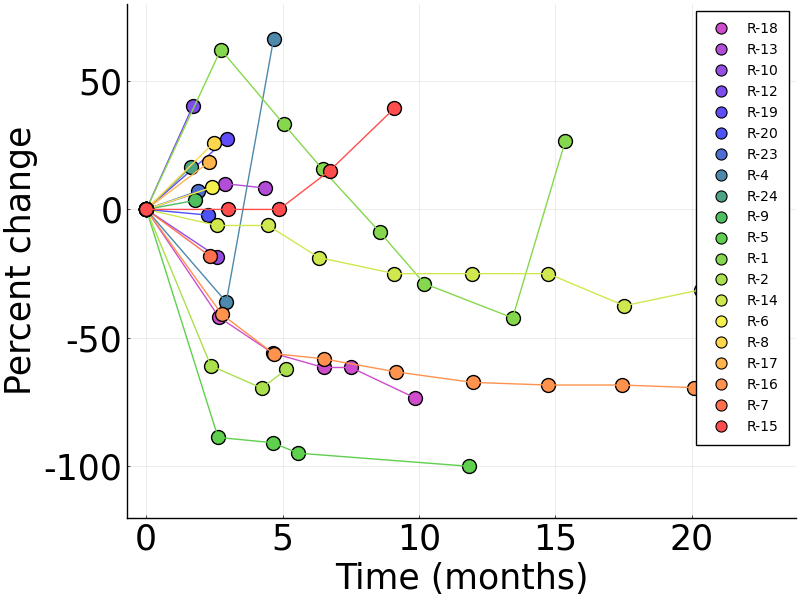

In [58]:
#plot percent change in sum of diameters by patient
plot()
tumor_classification = []
number_of_data_points = []
diameter_tumor_time = []
tumor_time = []
tumor_size = []
new_vector = []

for m = 1:20
    if m ∉ [5,12]
        m2 = 1
        diameter_tumor_time = []
        for i = patient_classification[m,1]:patient_classification[m,2]
            tumor_time = collect(skipmissing(data_array[2*i-1,:]))
            tumor_size = collect(skipmissing(data_array[2*i,:]))
            tumor_size = (2 .* tumor_size).^(1/3)
            
            diameter_tumor_time = vcat(diameter_tumor_time, [tumor_size])
            m2 = m2+1
        end
        
        new_vector = sum(reduce(hcat,diameter_tumor_time)', dims = 1)
        
        for j = 2:convert(Int64, length(tumor_size))
            new_vector[j] = (new_vector[j]-new_vector[1])./new_vector[1]
        end
        new_vector[1] = 0.0

        scatter!(tumor_time, new_vector', markersize = 10, size =(1600,600), font = "Ariel", label = patient_classification_array[m,1], color = color_vector_patient[m], legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
        plot!(tumor_time, new_vector', xticks = ([0,150,300,450,600],[0,5,10,15,20]), yticks = ([-1,-0.5,0,0.5],[-100,-50,0,50]), ylims = [-1.2,0.8], size =(800,600), font = "Ariel", color = color_vector_patient[m], label = false, legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (months)",xguidefontsize=25,ylabel="Percent change",yguidefontsize=25,title = "",titlefontsize=25)

    elseif m == 5
        tumor_time = [0,89]
        tumor_size = [0,0.274336283]
        
        scatter!(tumor_time, tumor_size, markersize = 10, size =(1600,600), font = "Ariel", label = patient_classification_array[m,1], color = color_vector_patient[m], legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
        plot!(tumor_time, tumor_size, xticks = ([0,150,300,450,600],[0,5,10,15,20]), yticks = ([-1,-0.5,0,0.5],[-100,-50,0,50]), ylims = [-1.2,0.8], size =(800,600), font = "Ariel", color = color_vector_patient[m], label = false, legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (months)",xguidefontsize=25,ylabel="Percent change",yguidefontsize=25,title = "",titlefontsize=25)

    elseif m == 12
        tumor_time = [0,82,151,194,257,306,403,461]
        tumor_size = [0,0.622222222,0.333333333,0.155555556,-0.088888889,-0.288888889,-0.422222222,0.266666667]
        
        scatter!(tumor_time, tumor_size, markersize = 10, size =(1600,600), font = "Ariel", label = patient_classification_array[m,1], color = color_vector_patient[m], legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
        plot!(tumor_time, tumor_size, xticks = ([0,150,300,450,600],[0,5,10,15,20]), yticks = ([-1,-0.5,0,0.5],[-100,-50,0,50]), ylims = [-1.2,0.8], size =(800,600), font = "Ariel", color = color_vector_patient[m], label = false, legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (months)",xguidefontsize=25,ylabel="Percent change",yguidefontsize=25,title = "",titlefontsize=25)
    end
end
plot!()

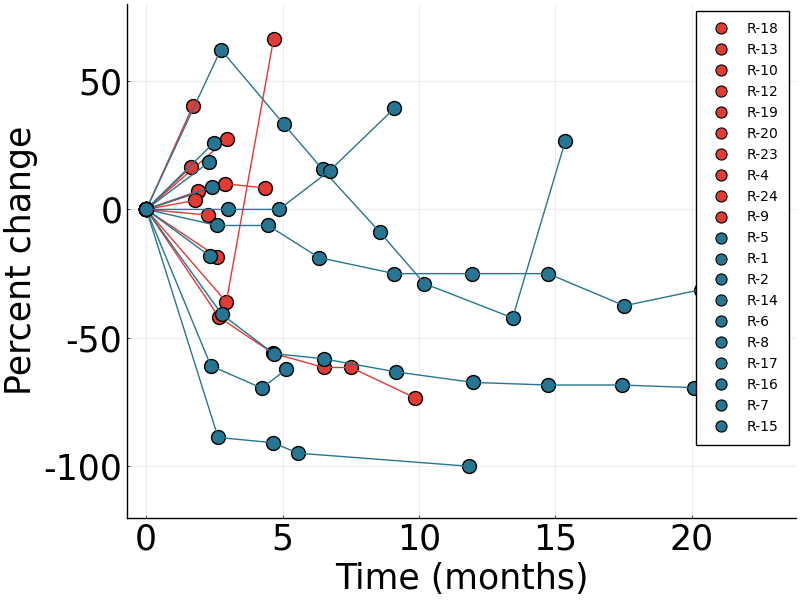

In [59]:
#plot percent change in sum of diameters by patient
plot()
tumor_classification = []
number_of_data_points = []
diameter_tumor_time = []
tumor_time = []
tumor_size = []
new_vector = []

for m = 1:20
    if m ∉ [5,12]
        m2 = 1
        diameter_tumor_time = []
        for i = patient_classification[m,1]:patient_classification[m,2]
            tumor_time = collect(skipmissing(data_array[2*i-1,:]))
            tumor_size = collect(skipmissing(data_array[2*i,:]))
            tumor_size = (2 .* tumor_size).^(1/3)
            
            diameter_tumor_time = vcat(diameter_tumor_time, [tumor_size])
            m2 = m2+1
        end
        
        new_vector = sum(reduce(hcat,diameter_tumor_time)', dims = 1)
        
        for j = 2:convert(Int64, length(tumor_size))
            new_vector[j] = (new_vector[j]-new_vector[1])./new_vector[1]
        end
        new_vector[1] = 0.0

        scatter!(tumor_time, new_vector', markersize = 10, size =(1600,600), font = "Ariel", label = patient_classification_array[m,1], color = color_vector_paper[m], legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
        plot!(tumor_time, new_vector', xticks = ([0,150,300,450,600],[0,5,10,15,20]), yticks = ([-1,-0.5,0,0.5],[-100,-50,0,50]), ylims = [-1.2,0.8], size =(800,600), font = "Ariel", color = color_vector_paper[m], label = false, legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (months)",xguidefontsize=25,ylabel="Percent change",yguidefontsize=25,title = "",titlefontsize=25)

    elseif m == 5
        tumor_time = [0,89]
        tumor_size = [0,0.274336283]
        
        scatter!(tumor_time, tumor_size, markersize = 10, size =(1600,600), font = "Ariel", label = patient_classification_array[m,1], color = color_vector_paper[m], legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
        plot!(tumor_time, tumor_size, xticks = ([0,150,300,450,600],[0,5,10,15,20]), yticks = ([-1,-0.5,0,0.5],[-100,-50,0,50]), ylims = [-1.2,0.8], size =(800,600), font = "Ariel", color = color_vector_paper[m], label = false, legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (months)",xguidefontsize=25,ylabel="Percent change",yguidefontsize=25,title = "",titlefontsize=25)

    elseif m == 12
        tumor_time = [0,82,151,194,257,306,403,461]
        tumor_size = [0,0.622222222,0.333333333,0.155555556,-0.088888889,-0.288888889,-0.422222222,0.266666667]
        
        scatter!(tumor_time, tumor_size, markersize = 10, size =(1600,600), font = "Ariel", label = patient_classification_array[m,1], color = color_vector_paper[m], legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
        plot!(tumor_time, tumor_size, xticks = ([0,150,300,450,600],[0,5,10,15,20]), yticks = ([-1,-0.5,0,0.5],[-100,-50,0,50]), ylims = [-1.2,0.8], size =(800,600), font = "Ariel", color = color_vector_paper[m], label = false, legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (months)",xguidefontsize=25,ylabel="Percent change",yguidefontsize=25,title = "",titlefontsize=25)
    end
end
plot!()

## Fit tumor data to mathematical model

In [ ]:
#fit tumors to mathematical model
number_of_samples = 2000
chain_runs = 4
chain_array = []

for i = 1:Int(size(data_array,1)/2)
    tumor_time = collect(skipmissing(data_array[2*i-1,:]))
    tumor_size = collect(skipmissing(data_array[2*i,:]))
    for j = 2:convert(Int64, length(tumor_size))
        tumor_size[j] = (tumor_size[j]-tumor_size[1])./tumor_size[1]
    end
    tumor_size[1] = 0.0
    
    popfirst!(tumor_time)
    popfirst!(tumor_size)
    
    tumor_curve_fit = zeros(length(tumor_size))
    for j = 1:convert(Int64, length(tumor_size))
        tumor_curve_fit[j] = tumor_size[j].*u0[1]+u0[1]
    end
        
    #fit tumor
    Turing.setadbackend(:forwarddiff)

    @model function fitlv(data, prob1)
        
        #β₁ ~ parameter_priors[1]
        #β₂ ~ parameter_priors[2]
        #β₃ ~ parameter_priors[3]
        #β₄ ~ parameter_priors[4]
        #α₆ ~ parameter_priors[5]
        #σ ~ parameter_priors[6]
        #p = [β₁, β₂, β₃, β₄, α₆]
        
        β₃ ~ parameter_priors[1]
        β₄ ~ parameter_priors[2]
        α₆ ~ parameter_priors[3]
        σ ~ parameter_priors[4]
        p = [β₃, β₄, α₆]
        
        prob = remake(prob1, p=p)
        predicted = solve(prob,Tsit5(),saveat=tumor_time,callback=floor_event,reltol=1e-6,isoutofdomain=(u,p,t)->any(x->x<0,u)) 

        for k = 1:min(length(predicted),length(tumor_curve_fit))
            data[k] ~ Normal(log.(predicted[k][1].+1), σ) 
        end

    end

    model = fitlv(log.(tumor_curve_fit.+1), prob1) 

    @time chain = sample(model, NUTS(0.65), MCMCThreads(), number_of_samples, chain_runs, progress=true)
    
    chain_array = Array(chain)
    save("chain_array$i.jld", "data", chain_array)

end

## Plot posterior parameter values

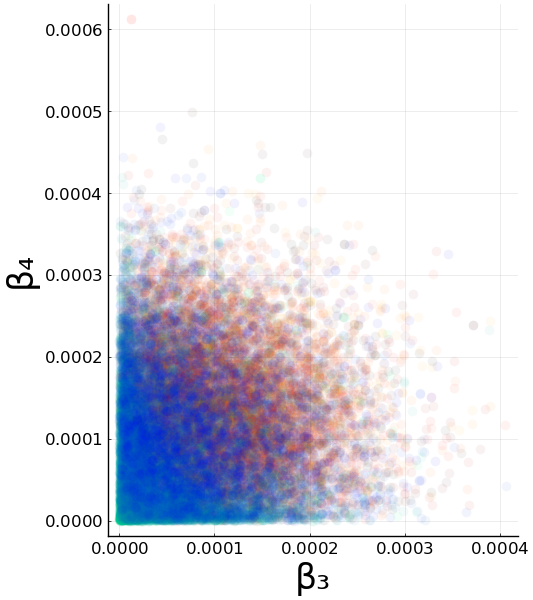

In [92]:
#concatenate chains and plot posteriors
number_of_samples = 2000
chain_runs = 4
big_chain = zeros(number_of_samples.*chain_runs,number_of_parameters+1,number_of_tumors)
for i = 1:number_of_tumors
    big_chain[:,:,i] = load("chain_array$i.jld")["data"]
end

big_chain_sorted_increasing = big_chain[:,:,tumor_increasing_sorted[:,1]]
big_chain_sorted_decreasing = big_chain[:,:,tumor_decreasing_sorted[:,1]]

#plot joint posteriors
dots_to_plot = 500
scatter()
label_one =[]
label_two = []

m = rand(1:number_of_samples*chain_runs, dots_to_plot)

for j = 1:1 #1:3
    for k = 2:2 #1:3
        for i = 1:convert(Int64, length(tumor_increasing_sorted)/2)
            label_one = parameters_symbols[j]
            label_two = parameters_symbols[k]
            scatter!(big_chain_sorted_increasing[m,j,i], big_chain_sorted_increasing[m,k,i], markersize = 7, markercolor = color_vector_increasing[i], markerstrokewidth = 0, markeralpha = 0.05, xlab = label_one, ylab = label_two, legend = :false, size = (1600/3,600), font = "Ariel", xtickfontsize=12,ytickfontsize=12,xguidefontsize=25,yguidefontsize=25,titlefontsize=25)
        end
        
        for i = 1:convert(Int64, length(tumor_decreasing_sorted)/2)
            label_one = parameters_symbols[j]
            label_two = parameters_symbols[k]
            scatter!(big_chain_sorted_decreasing[m,j,i], big_chain_sorted_decreasing[m,k,i], markersize = 7, markercolor = color_vector_decreasing[i], markerstrokewidth = 0, markeralpha = 0.05, xlab = label_one, ylab = label_two, legend = :false, size = (1600/3,600), font = "Ariel", xtickfontsize=12,ytickfontsize=12,xguidefontsize=25,yguidefontsize=25,titlefontsize=25)
        end
    end
end
plot!()

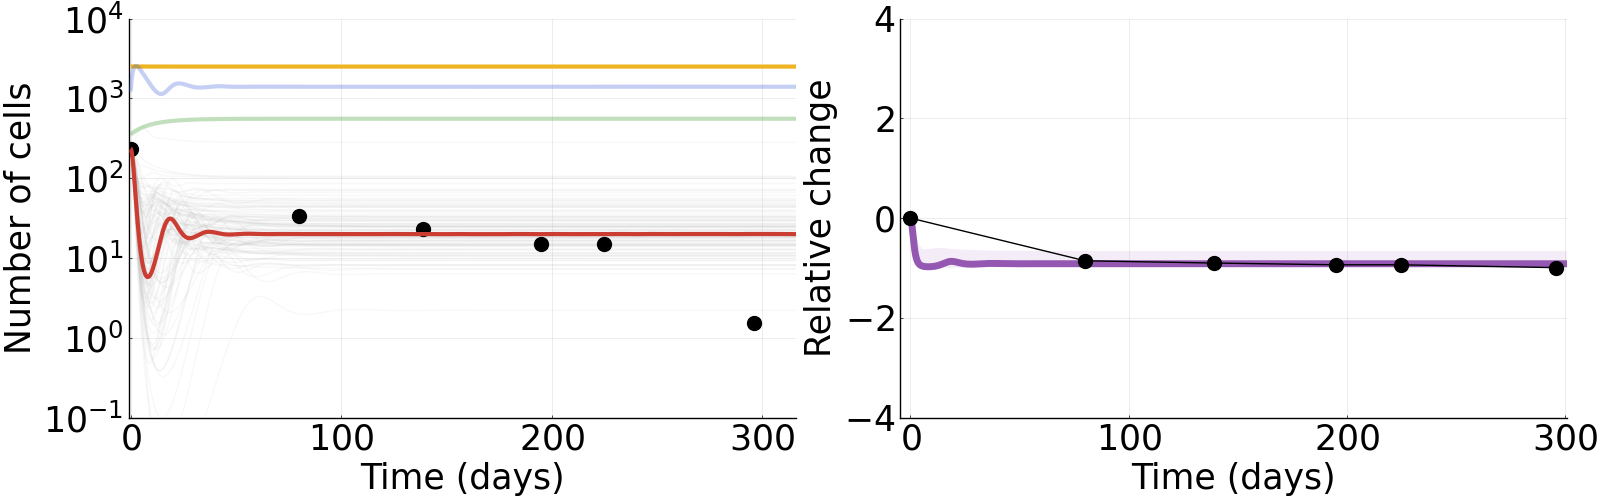

In [89]:
#plot tumor fits
plot()
vector_prob_median  = []
vector_sol_median = []
for i = 1:number_of_tumors

    for j = 1:number_of_parameters
        parameters[j] = median(big_chain[:,j,i]) 
    end
    
    p = parameters
    probplot = ODEProblem(ode_system,u0,tspan,p)
    solplotsmooth = solve(probplot,alg,saveat=0.1,callback=floor_event)
    push!(vector_prob_median,probplot)
    push!(vector_sol_median,solplotsmooth) 
    
end

fitting_plot = []

for i = 1:1 #55

    tumor_time = collect(skipmissing(data_array[2*i-1,:]))
    tumor_size = collect(skipmissing(data_array[2*i,:]))
    for j = 2:convert(Int64, length(tumor_size))
        tumor_size[j] = (tumor_size[j]-tumor_size[1])./tumor_size[1]
    end
    tumor_size[1] = 0.0
    
    tumor_number = zeros(length(tumor_size))
    tumor_number = u0[1].*tumor_size .+ u0[1]

    plot()
    resol = solve(remake(prob1,p=big_chain[rand(1:length(big_chain[:,1,i])), 1:number_of_parameters+1,i]),Tsit5(),saveat=0.1,callback=floor_event,reltol=1e-6,isoutofdomain=(u,p,t)->any(x->x<0,u))

    for k in 1:100
        resol = solve(remake(prob1,p=big_chain[rand(1:length(big_chain[:,1,i])), 1:number_of_parameters+1,i]),Tsit5(),saveat=0.1,callback=floor_event,reltol=1e-6,isoutofdomain=(u,p,t)->any(x->x<0,u))
        plot!(resol.t, resol[1,:], alpha=0.1, color = "#BBBBBB", legend = false, yaxis=:log,size =(1600/2,600), font = "Ariel", ylims = (0.01,10^7.5), xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Number of cells",yguidefontsize=25,title = "")
    end
    scatter!(tumor_time, tumor_number, markersize = 10, markercolor = "Black")
    a = plot!(resol.t, transpose(vector_sol_median[i]), w=3, yaxis=:log,size =(1600/2,600), font = "Ariel", xlims = [-1,last(tumor_time)+20], ylims = (10^-1,10^4), color = [logocolors.red "goldenrod2" logocolors.green logocolors.blue], alpha = [1 1 0.3 0.3], legend = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Number of cells",yguidefontsize=25,title = "",titlefontsize=25)
    
    scatter()
    traj = solve(remake(vector_prob_median[i],p=big_chain[1, 1:number_of_parameters+1, i]),Tsit5(),saveat=0.1,callback=floor_event,reltol=1e-6,isoutofdomain=(u,p,t)->any(x->x<0,u)) 
    array_of_traj = zeros(number_of_samples*chain_runs, length(traj.t))
    for k in 1:number_of_samples*chain_runs
        resol_tumor = solve(remake(vector_prob_median[i],p=big_chain[k, 1:number_of_parameters+1, i]),Tsit5(),saveat=0.1,callback=floor_event,reltol=1e-6,isoutofdomain=(u,p,t)->any(x->x<0,u)) 
        for j = 1:convert(Int64, length(resol_tumor)) 
            array_of_traj[k,j] = (resol_tumor[j][1]-u0[1])./u0[1]
        end
    end
    interval_low = zeros(length(traj.t))
    interval_high = zeros(length(traj.t))
    for k in 1:length(interval_low)
        interval_low[k] = quantile(array_of_traj[:,k], 0.05)
        interval_high[k] = quantile(array_of_traj[:,k], 0.95)
    end
    
    ode_solution = vector_sol_median[i]
    predicted_data = ones(length(ode_solution)) 
    for j = 1:convert(Int64, length(ode_solution))
        predicted_data[j] = (ode_solution[j][1]-u0[1])./u0[1]
    end
    plot!(ode_solution.t, predicted_data, ribbon = (abs.(interval_low-predicted_data), abs.(interval_high-predicted_data)),fillalpha= 0.1, linewidth = 5, xlims = (-5,last(tumor_time)+5), size =(1600/2,600), font = "Ariel", color = logocolors.purple, legend = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
    plot!(tumor_time, tumor_size, xlims = (-5,last(tumor_time)+5), size =(1600/2,600), font = "Ariel", color = "Black", legend = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
    b = scatter!(tumor_time, tumor_size, markersize = 10, xlims = (-5,last(tumor_time)+5), ylims = (-4,4), size =(1600/2,600), font = "Ariel", markercolor = "Black", legend = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
    
    fitting_plot = plot(a, b, layout = (1,2), size = (1600,500))
    
    plot()
   
end
fitting_plot

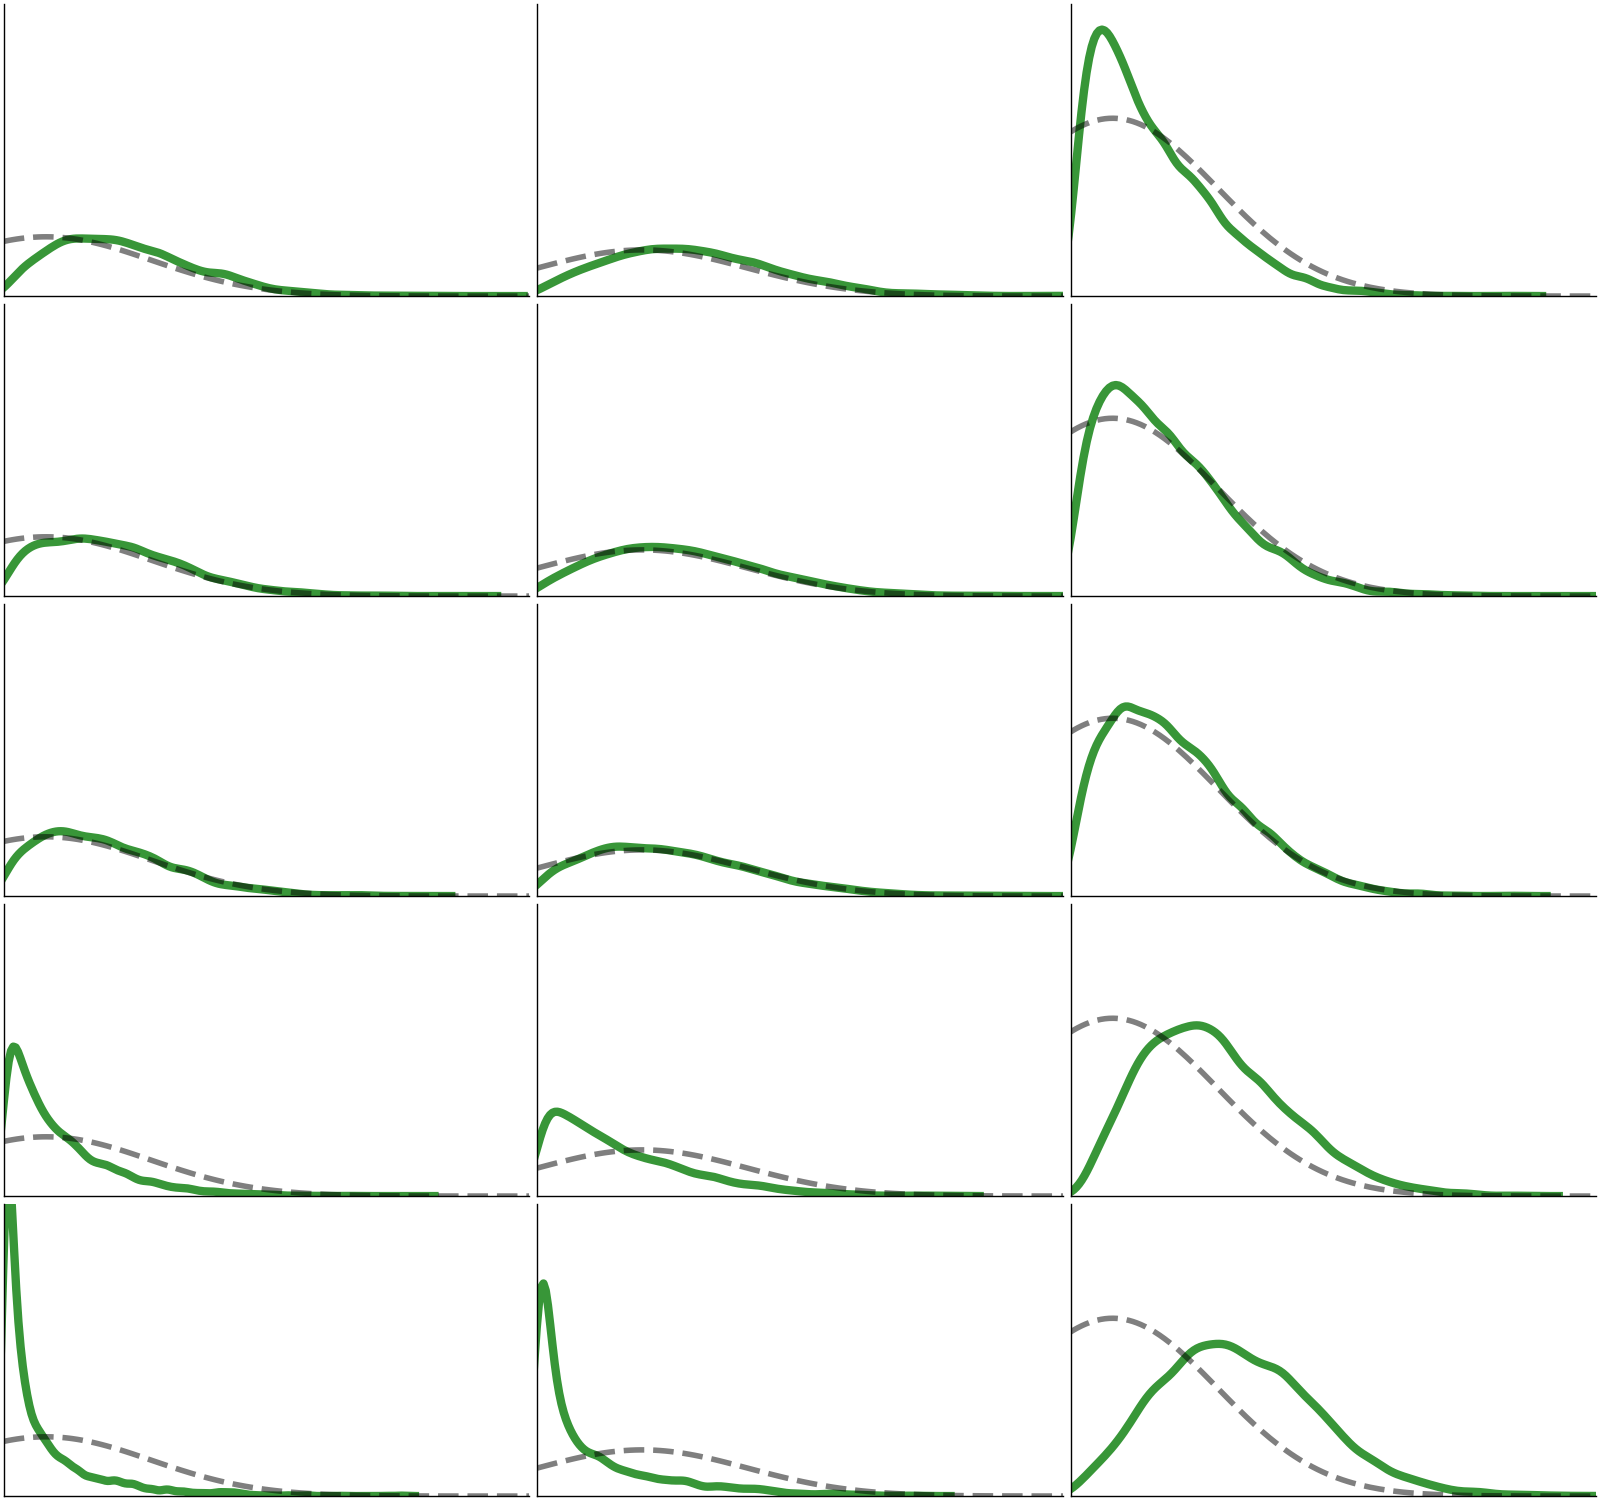

In [93]:
#plot posteriors from select tumors
plot()
vector_of_plots = Array{Plots.Plot{Plots.PyPlotBackend},1}()
chain_array = []

vector_xmins = [0.0, 0.0, 0.0]
vector_xmaxs = [0.0005, 0.0005, 0.05]
vector_ymins = [0.0, 0.0, 0.0]
vector_ymaxs = [3*10^4, 3*10^4, 100]

for i = [20,24,15,32,27]

    chain_array = big_chain[:,:,i]
    
    plot()
    for j = 1:number_of_parameters
        plot()
        title = parameters_symbols[j]
        plot!(density(chain_array[:,j], linewidth = 6, alpha = 0.9, color = "forestgreen"))
        if i == 1
            plot_chain = plot!(parameter_priors[j], linewidth = 4, xlims = [vector_xmins[j],vector_xmaxs[j]], ylims = [vector_ymins[j],vector_ymaxs[j]], style = :dash, alpha = 0.5, legend = false, color = "black", size = (1600/6,600), font = "Ariel", title="$title", xtickfontsize=10,ytickfontsize=10,xguidefontsize=10,yguidefontsize=10,titlefontsize=40)
        else
            plot_chain = plot!(parameter_priors[j], linewidth = 4, xlims = [vector_xmins[j],vector_xmaxs[j]], ylims = [vector_ymins[j],vector_ymaxs[j]], style = :dash, alpha = 0.5, legend = false, color = "black", size = (1600/6,600), font = "Ariel", title="", xtickfontsize=10,ytickfontsize=10,xguidefontsize=10,yguidefontsize=10,titlefontsize=40)
        end
        plot!(xticks = :none, yticks = :none)
        push!(vector_of_plots, plot_chain) 
    end
end
plot(vector_of_plots..., layout = (5,number_of_parameters), size = (1600,1500), plot_title ="", titlefontsize=tfsize)

## Decision trees

In [124]:
#define decision trees for increasing vs decreasing tumors
chain_data = cat(big_chain_sorted_decreasing,big_chain_sorted_increasing, dims = 3)

chain_data2 = zeros(440000,4)
for i = 1:number_of_tumors
    chain_data2[(i-1)*8000+1:i*8000,:] = chain_data[:,:,i]
end
chain_data2

chain_classification = Vector{String}(undef, number_of_tumors*number_of_samples*chain_runs)
for i = 1:convert(Int64, length(tumor_decreasing_sorted)/2)*number_of_samples*chain_runs
    chain_classification[i] = "decreasing"
end
for i = convert(Int64, length(tumor_decreasing_sorted)/2)*number_of_samples*chain_runs+1:number_of_tumors*number_of_samples*chain_runs
    chain_classification[i] = "increasing"
end

powerset(parameters_symbols)

8-element Vector{Vector{Symbol}}:
 []
 [:β₃]
 [:β₄]
 [:β₃, :β₄]
 [:α₆]
 [:β₃, :α₆]
 [:β₄, :α₆]
 [:β₃, :β₄, :α₆]

In [125]:
#run decision trees
results_mean = zeros(length(powerset(parameters_numbers)))
results_std = zeros(length(powerset(parameters_numbers)))
results_min = zeros(length(powerset(parameters_numbers)))
results_max = zeros(length(powerset(parameters_numbers)))
chain_to_analyze = []
for i = 2:length(powerset(parameters_numbers))
    
    chain_to_analyze = copy(chain_data2[:,powerset(parameters_numbers)[i]])
    
    #run decision tree on parameters from MCMC posteriors
    features = float.(chain_to_analyze)
    labels   = string.(chain_classification)
    # train depth-truncated classifier
    model = DecisionTreeClassifier(max_depth=3)
    #fit model
    fit!(model, features, labels)
    #print tree
    #print_tree(model, 3)
    #run n-fold cross validation over 3 CV folds
    accuracy = cross_val_score(model, features, labels, cv=3)
    results_mean[i] = 100*mean(accuracy)
    results_std[i] = 100*std(accuracy)
    results_min[i] = 100*minimum(accuracy)
    results_max[i] = 100*maximum(accuracy)
end

results = DataFrame(features_for_prediction=powerset(parameters_symbols), mean=results_mean, standard_deviation=results_std, min_of_range=results_min, max_of_range=results_max)
results_df = deleteat!(results, 1)

Row,features_for_prediction,mean,standard_deviation,min_of_range,max_of_range
,Array…,Float64,Float64,Float64,Float64
1,[:β₃],65.7138,8.68025,55.8343,72.1176
2,[:β₄],65.0104,7.45577,56.5128,70.4553
3,"[:β₃, :β₄]",68.9675,11.0951,56.1623,75.72
4,[:α₆],64.72,3.70596,60.5573,67.6605
5,"[:β₃, :α₆]",66.9182,9.948,55.563,74.0983
6,"[:β₄, :α₆]",66.2541,10.0677,54.7339,73.364
7,"[:β₃, :β₄, :α₆]",68.8259,13.716,53.1112,78.3907


In [126]:
#define decision trees for tumors by site
big_chain = zeros(number_of_samples.*chain_runs,number_of_parameters+1,number_of_tumors)
for i = 1:number_of_tumors
    big_chain[:,:,i] = load("chain_array$i.jld")["data"]
end

lung = findall(x->x=="Lung", data_location_general_array)
liver = findall(x->x=="Liver", data_location_general_array)
L = LinearIndices(data_location_general_array)

chain_data_lung = big_chain[:,:,L[lung]]
chain_data_liver = big_chain[:,:,L[liver]]

chain_data_liver2 = zeros(length(L[liver])*8000,4)
for i = 1:length(L[liver])
    chain_data_liver2[(i-1)*8000+1:i*8000,:] = chain_data_liver[:,:,i]
end
chain_data_liver2

chain_data_lung2 = zeros(length(L[lung])*8000,4)
for i = 1:length(L[lung])
    chain_data_lung2[(i-1)*8000+1:i*8000,:] = chain_data_lung[:,:,i]
end
chain_data_lung2

chain_data2 = cat(chain_data_liver2, chain_data_lung2, dims = 1)

chain_classification = Vector{String}(undef, (length(L[liver])+length(L[lung]))*number_of_samples*chain_runs)
for i = 1:(length(L[liver]))*number_of_samples*chain_runs
    chain_classification[i] = "liver"
end
for i = (length(L[liver]))*number_of_samples*chain_runs+1:(length(L[liver])+length(L[lung]))*number_of_samples*chain_runs
    chain_classification[i] = "lung"
end

powerset(parameters_symbols)

8-element Vector{Vector{Symbol}}:
 []
 [:β₃]
 [:β₄]
 [:β₃, :β₄]
 [:α₆]
 [:β₃, :α₆]
 [:β₄, :α₆]
 [:β₃, :β₄, :α₆]

In [127]:
#run decision trees
results_mean = zeros(length(powerset(parameters_numbers)))
results_std = zeros(length(powerset(parameters_numbers)))
results_min = zeros(length(powerset(parameters_numbers)))
results_max = zeros(length(powerset(parameters_numbers)))
chain_to_analyze = []
for i = 2:length(powerset(parameters_numbers))
    
    chain_to_analyze = copy(chain_data2[:,powerset(parameters_numbers)[i]])
    
    #run decision tree on parameters from MCMC posteriors
    features = float.(chain_to_analyze)
    labels   = string.(chain_classification)
    # train depth-truncated classifier
    model = DecisionTreeClassifier(max_depth=3)
    #fit model
    fit!(model, features, labels)
    #print tree
    #print_tree(model, 3)
    #run n-fold cross validation over 3 CV folds
    accuracy = cross_val_score(model, features, labels, cv=3)
    results_mean[i] = 100*mean(accuracy)
    results_std[i] = 100*std(accuracy)
    results_min[i] = 100*minimum(accuracy)
    results_max[i] = 100*maximum(accuracy)
end

results = DataFrame(features_for_prediction=powerset(parameters_symbols), mean=results_mean, standard_deviation=results_std, min_of_range=results_min, max_of_range=results_max)
results_df = deleteat!(results, 1)

Row,features_for_prediction,mean,standard_deviation,min_of_range,max_of_range
,Array…,Float64,Float64,Float64,Float64
1,[:β₃],66.8735,3.18718,63.3666,69.5937
2,[:β₄],65.397,3.4705,61.6251,68.4552
3,"[:β₃, :β₄]",71.788,3.04653,68.6452,74.7281
4,[:α₆],62.656,2.75083,59.9286,65.4297
5,"[:β₃, :α₆]",70.557,3.81983,66.3907,73.8941
6,"[:β₄, :α₆]",69.1305,3.87338,65.0062,72.6911
7,"[:β₃, :β₄, :α₆]",74.339,3.253,70.8937,77.3576


## Simulation of virtual tumors

In [153]:
#define relevant chains
big_chain = zeros(number_of_samples.*chain_runs,number_of_parameters+1,number_of_tumors)
for i = 1:number_of_tumors
    big_chain[:,:,i] = load("chain_array$i.jld")["data"]
end

liver = findall(x->x=="Liver", data_location_general_array)
L = LinearIndices(data_location_general_array)
L[liver]

chain_data_liver = big_chain[:,:,L[liver]]

chain_data_liver2 = zeros(length(L[liver])*8000,4)
for i = 1:length(L[liver])
    chain_data_liver2[(i-1)*8000+1:i*8000,:] = chain_data_liver[:,:,i]
end

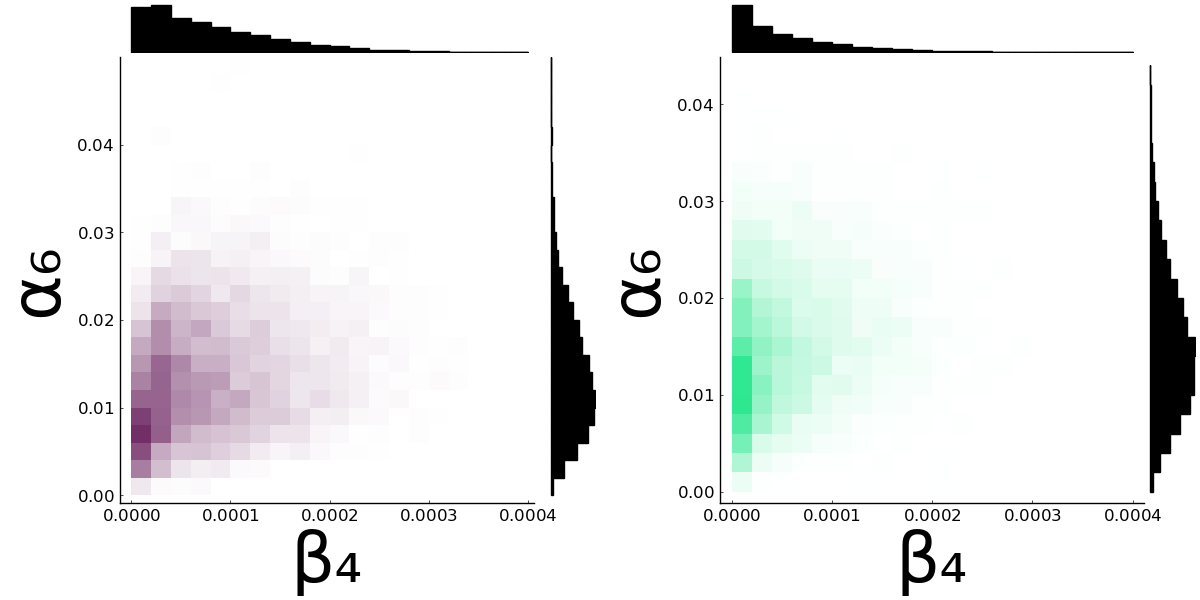

In [155]:
#plot marginal histograms
plot()

color_bar_site = [RGBA{Float64}(0.44313725490196076,0.1803921568627451,0.403921568627451,0.0), RGBA{Float64}(0.44313725490196076,0.1803921568627451,0.403921568627451,0.25), RGBA{Float64}(0.44313725490196076,0.1803921568627451,0.403921568627451,0.5), RGBA{Float64}(0.44313725490196076,0.1803921568627451,0.403921568627451,0.75), RGBA{Float64}(0.44313725490196076,0.1803921568627451,0.403921568627451,1.0)]
color_bar_patient = [RGBA{Float64}(45/250, 227/250, 169/300,0.0), RGBA{Float64}(45/250, 227/250, 169/300,0.25), RGBA{Float64}(45/250, 227/250, 169/300,0.5), RGBA{Float64}(45/250, 227/250, 169/300,0.75), RGBA{Float64}(45/250, 227/250, 169/300,1.0)]
color10 = RGBA{Float64}(45/250, 227/250, 169/300,1.0)

j = 2
i = 1
k = 3

patient_number = 1
    chain_data_patient_classification = big_chain[:,:,patient_classification[patient_number,1]:patient_classification[patient_number,2]]

    chain_data_patient_classification2 = zeros((patient_classification[patient_number,2] - patient_classification[patient_number,1] + 1)*8000,4)
    for i = 1:(patient_classification[patient_number,2] - patient_classification[patient_number,1] + 1)
        chain_data_patient_classification2[(i-1)*8000+1:i*8000,:] = chain_data_patient_classification[:,:,i]
    end
label_one = parameters_symbols[j]
label_two = parameters_symbols[k]
a = marginalhist(chain_data_lung[:,j,i], chain_data_lung[:,k,i], color = palette([:white, color_vector[1]], 2), xlab = "$label_one", ylab = "$label_two", size = (1600/3,600), font = "Ariel", xtickfontsize=12,ytickfontsize=12,xguidefontsize=50,yguidefontsize=50,titlefontsize=50, legend = false)
b = marginalhist(chain_data_patient_classification[:,j,i], chain_data_patient_classification[:,k,i], color = palette([:white, color10], 2), xlab = "$label_one", ylab = "$label_two", size = (1600/3,600), font = "Ariel", xtickfontsize=12,ytickfontsize=12,xguidefontsize=50,yguidefontsize=50,titlefontsize=50, legend = false)

plot(a,b, size = (1200,600))

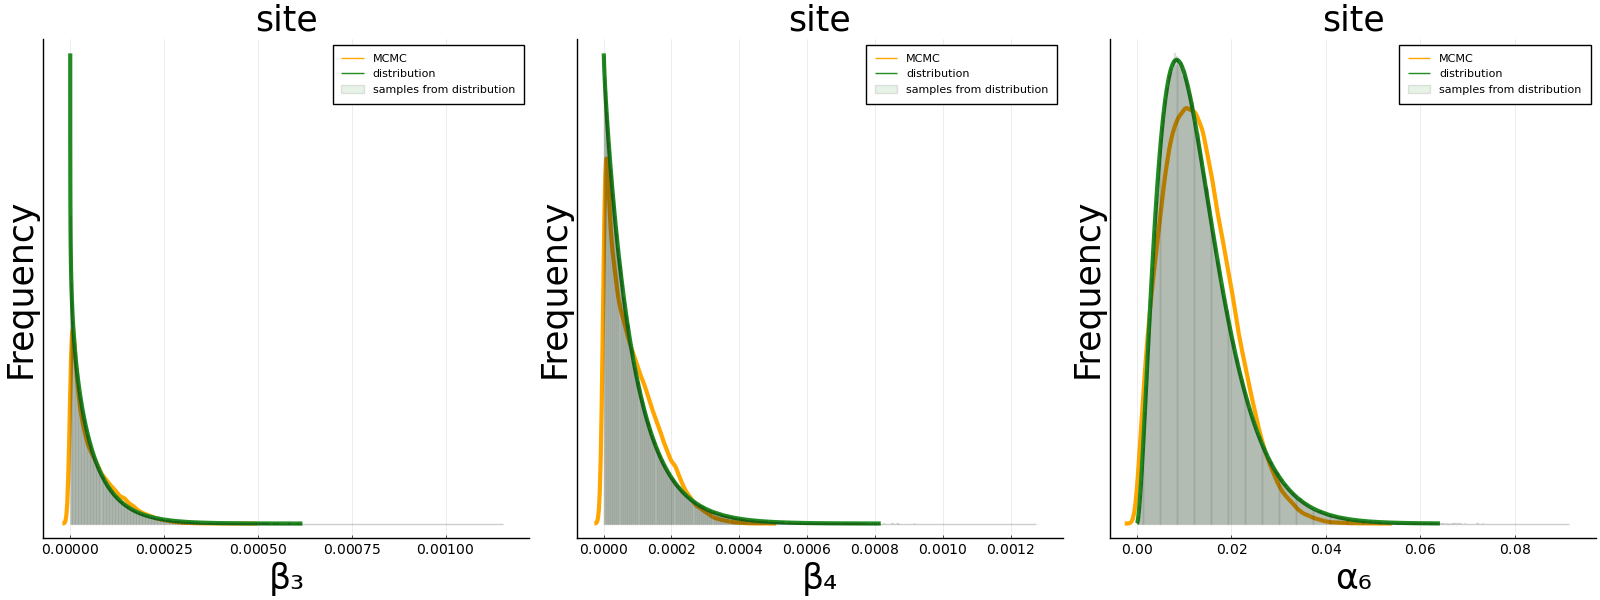

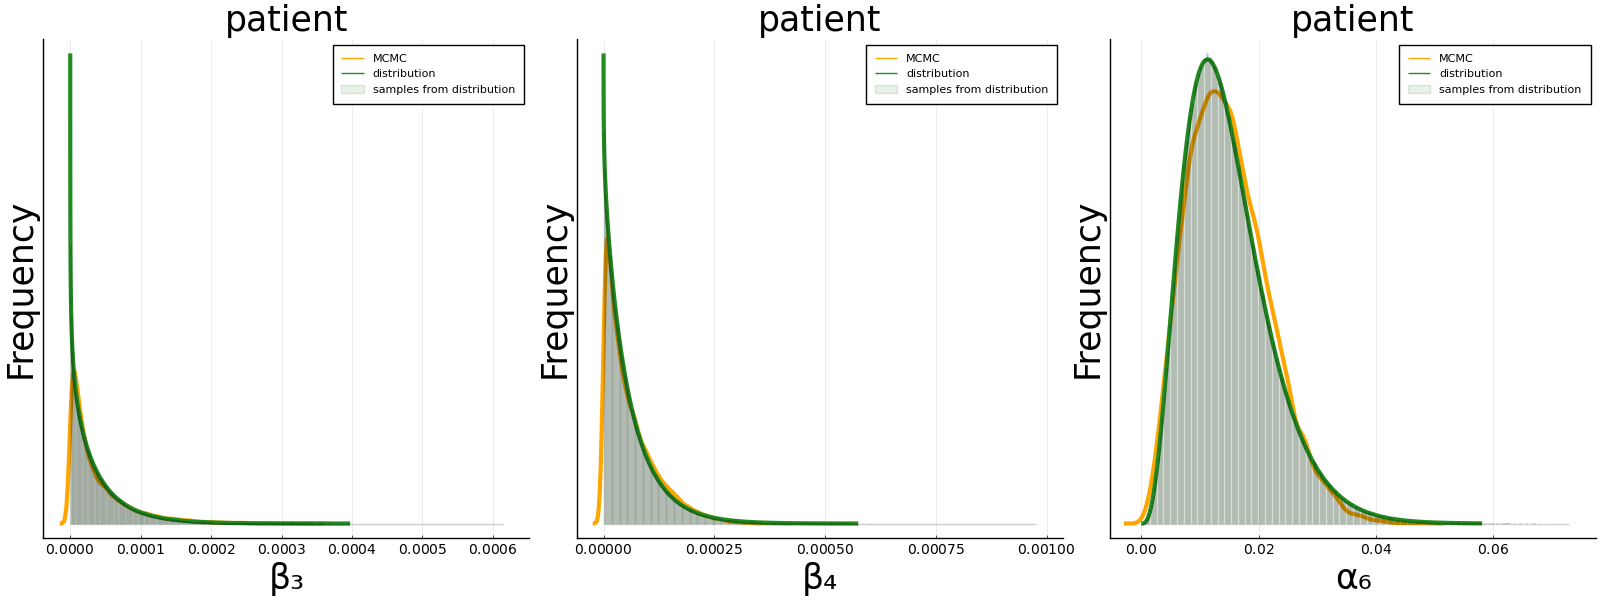

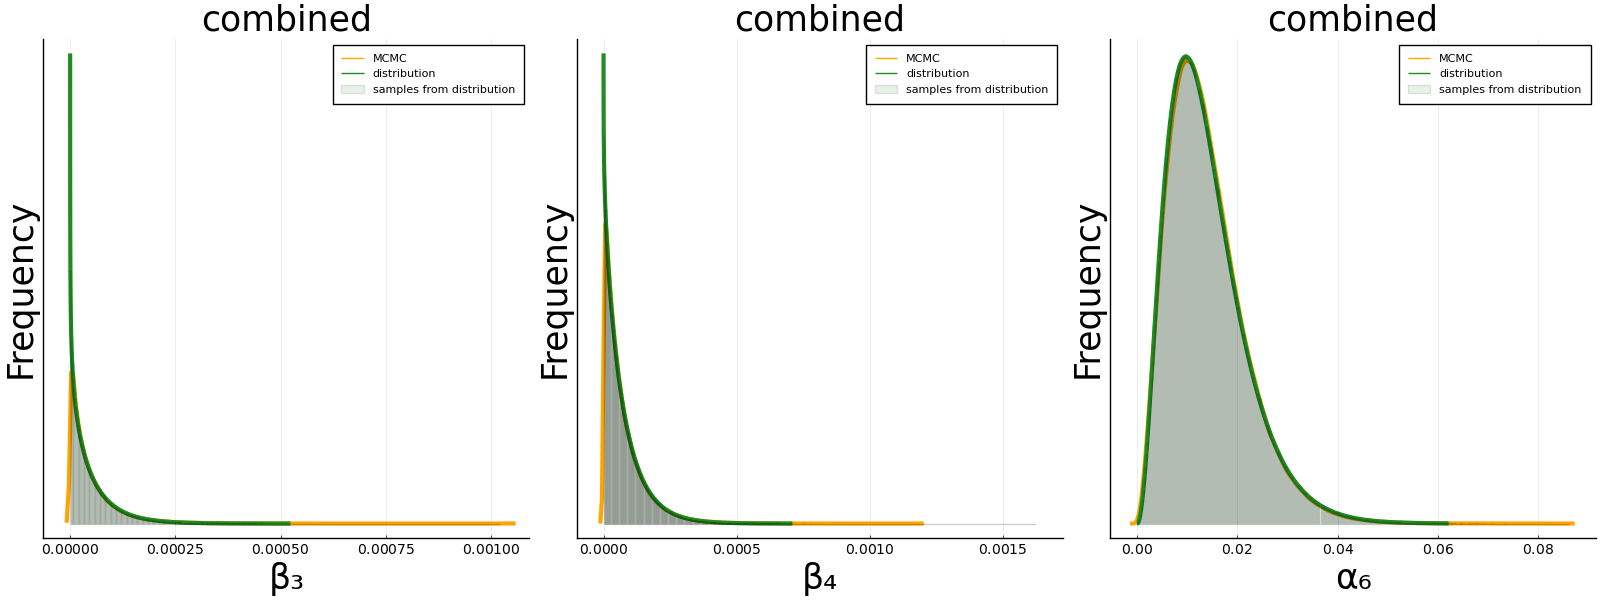

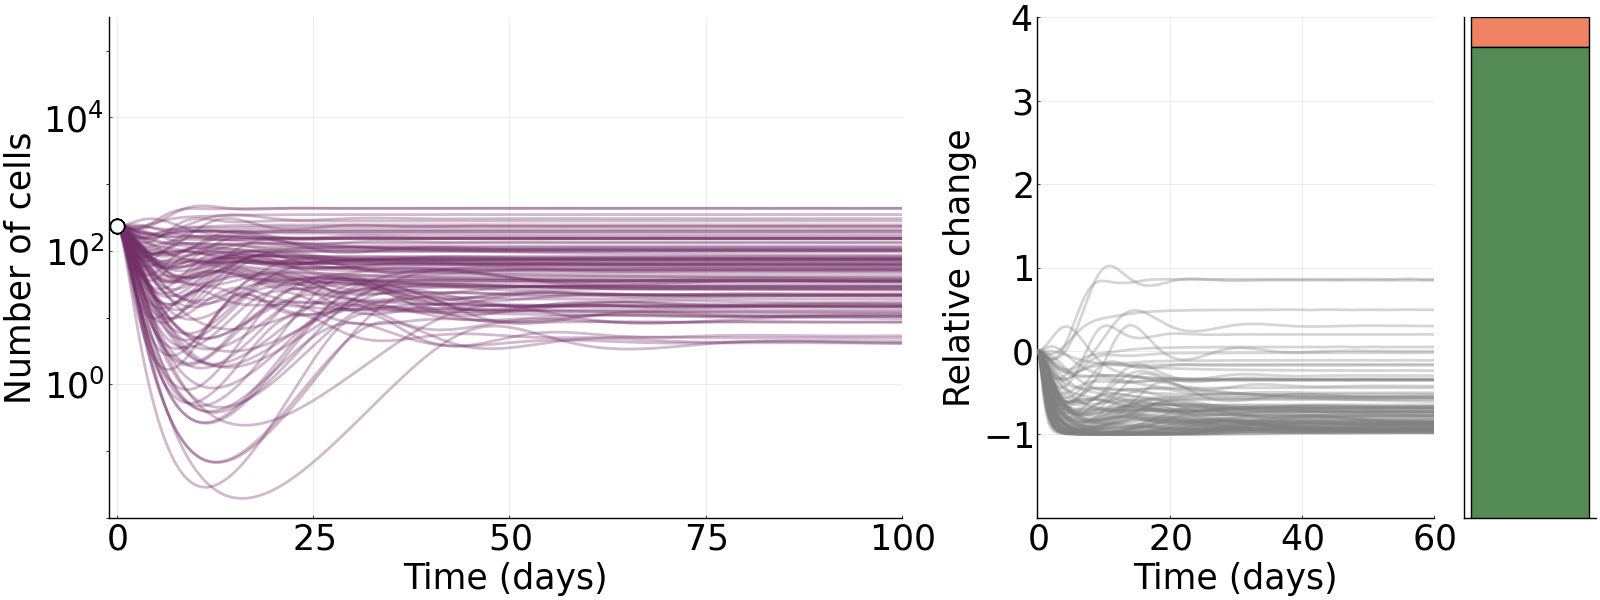

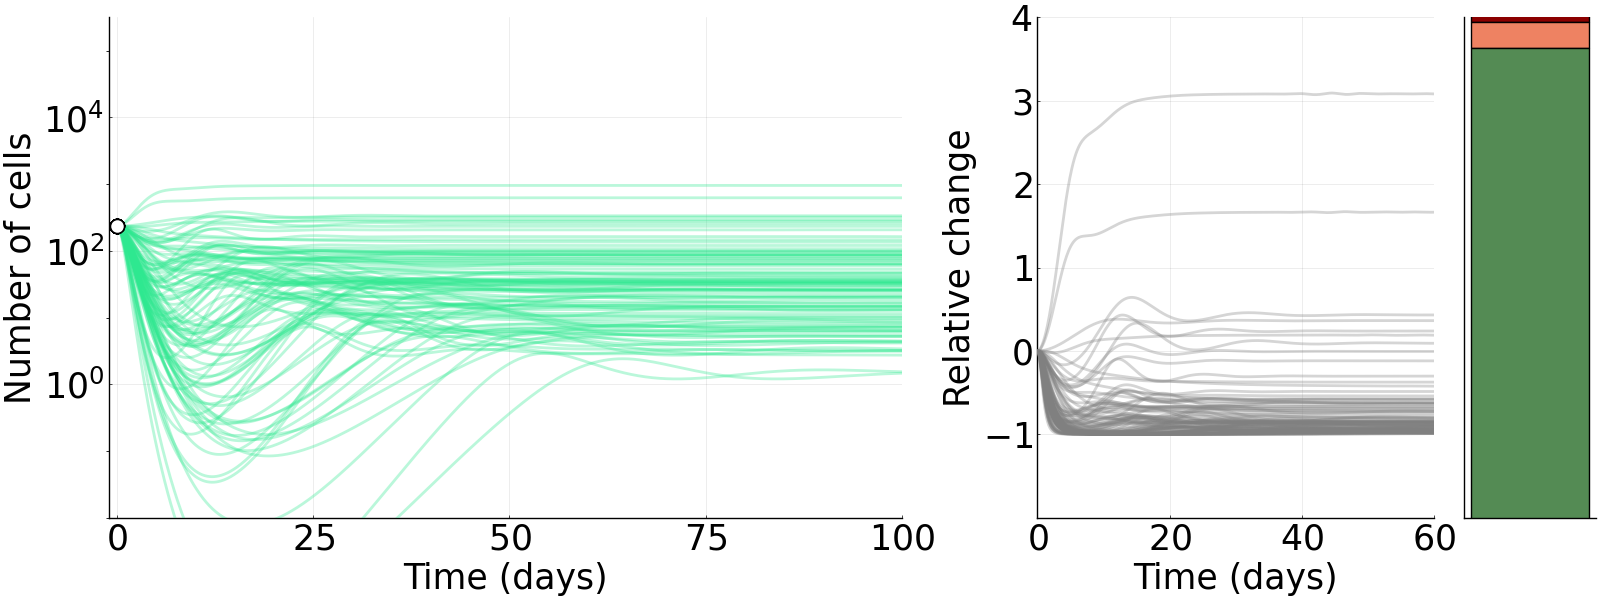

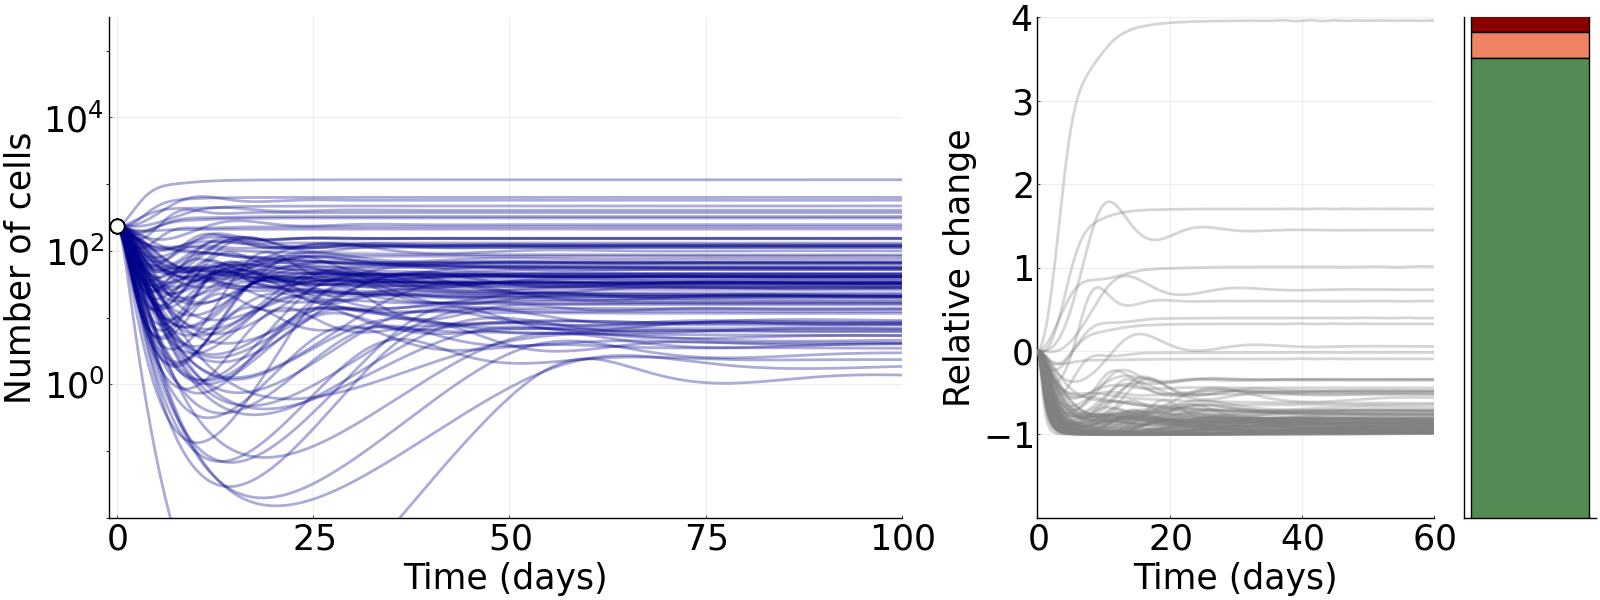

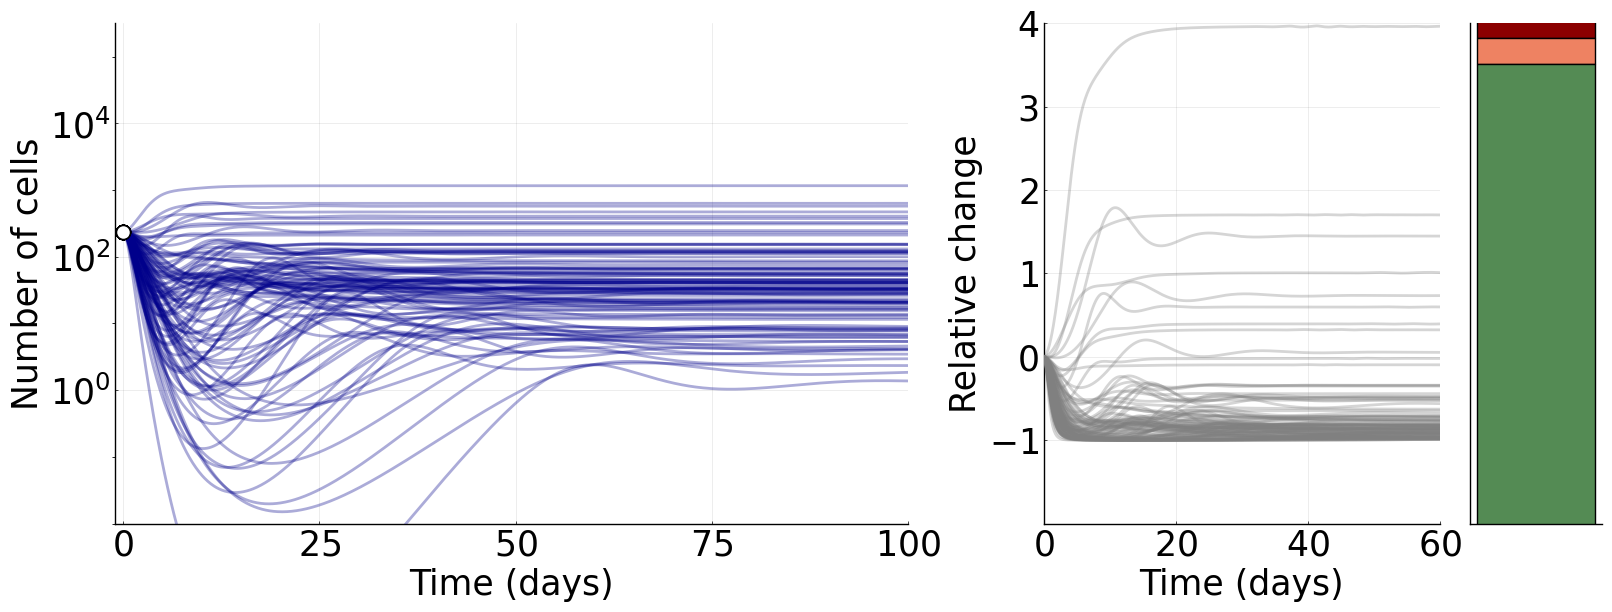

In [160]:
#plot fitted distributions and virtual tumors based on site, patient, and site + patient

plot()
tumor_classification = []
number_of_data_points = []
average_tumor_time = []
tumor_time = []

stats = zeros(3)

color10 = RGBA{Float64}(45/250, 227/250, 169/300,1.0)

for patient_number = 1:1 #1:20
    
    if patient_number ∉ [12]
        plot()
        m2 = 1
        average_tumor_time = []
        for i = patient_classification[patient_number,1]:patient_classification[patient_number,2]
            tumor_time = collect(skipmissing(data_array[2*i-1,:]))
            tumor_size = collect(skipmissing(data_array[2*i,:]))
            for j = 2:convert(Int64, length(tumor_size))
                tumor_size[j] = (tumor_size[j]-tumor_size[1])./tumor_size[1]
            end
            tumor_size[1] = 0.0
            push!(number_of_data_points, length(tumor_size))

            if last(tumor_size) > 0
                push!(tumor_classification, "increasing")
            else
                push!(tumor_classification, "decreasing")
            end

            average_tumor_time = append!(average_tumor_time, [tumor_size])

            scatter!(tumor_time, tumor_size, markersize = 10, size =(1600,600), font = "Ariel", color = palette(:tab10)[m2], label = data_location_array[patient_classification[patient_number,1]+m2-1], legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)

            plot!(tumor_time, tumor_size, ylims = [-2,4], size =(1600,600), font = "Ariel", color = palette(:tab10)[m2], label = false, legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)

            m2 = m2+1
        end

        scatter!(tumor_time, mean(average_tumor_time), markersize = 10, size =(1600,600), font = "Ariel", color = "gray", label = "average", legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
        plot!(tumor_time, mean(average_tumor_time), ylims = [-2,4], size =(1600,600), font = "Ariel", color = "gray", label = false, legendfont = 10, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)

        titletext1 = patient_classification_array[patient_number,1]
        titletext2 = patient_classification_array[patient_number,2]
        titletext3 = patient_classification_array[patient_number,3]
        titletext4 = patient_classification_array[patient_number,4]
        top_plot = plot!(title = "patient $patient_number, $titletext1, $titletext2, $titletext3, $titletext4")
    end
    
    
    stats = zeros(3)


    chain_data_patient_classification = big_chain[:,:,patient_classification[patient_number,1]:patient_classification[patient_number,2]]

    chain_data_patient_classification2 = zeros((patient_classification[patient_number,2] - patient_classification[patient_number,1] + 1)*8000,4)
    for i = 1:(patient_classification[patient_number,2] - patient_classification[patient_number,1] + 1)
        chain_data_patient_classification2[(i-1)*8000+1:i*8000,:] = chain_data_patient_classification[:,:,i]
    end


    number_of_sims = 100
    sol_tumor = zeros(number_of_sims,Int(tspan[2]).*10+1)
    new_sol_full = zeros(number_of_sims,Int(tspan[2]).*10+1)



    p_rand = zeros(3)
    
    
    
    plot()
    location_dist1 = fit(Gamma, chain_data_lung2[:,1])
    location_sample1 = rand(Truncated(location_dist1,0.0,1.0),1000000)
    density!(chain_data_lung2[:,1], label = "MCMC", color = "orange", width = 3)
    plot!(location_dist1, label = "distribution", color = "forestgreen", width = 3)
    location_distplot1 = histogram!(location_sample1, label = "samples from distribution", color = "forestgreen", alpha = 0.1, normalize=:pdf, xlabel="β₃")

    plot()
    location_dist2 = fit(Gamma, chain_data_lung2[:,2])
    location_sample2 = rand(Truncated(location_dist2,0.0,1.0),1000000)
    density!(chain_data_lung2[:,2], label = "MCMC", color = "orange", width = 3)
    plot!(location_dist2, label = "distribution", color = "forestgreen", width = 3)
    location_distplot2 = histogram!(location_sample2, label = "samples from distribution", color = "forestgreen", alpha = 0.1, normalize=:pdf, xlabel="β₄")

    plot()
    location_dist3 = fit(Gamma, chain_data_lung2[:,3])
    location_sample3 = rand(Truncated(location_dist3,0.0,1.0),1000000)
    density!(chain_data_lung2[:,3], label = "MCMC", color = "orange", width = 3)
    plot!(location_dist3, label = "distribution", color = "forestgreen", width = 3)
    location_distplot3 = histogram!(location_sample3, label = "samples from distribution", color = "forestgreen", alpha = 0.1, normalize=:pdf, xlabel="α₆")

    display(plot(location_distplot1, location_distplot2, location_distplot3, layout = grid(1,3), size = (1600,600), title = "site", font = "Ariel", yticks = :none, xtickfontsize=10, ytickfontsize=25, xguidefontsize=25, ylabel="Frequency", yguidefontsize=25, titlefontsize=25))
    
    
    plot()
    patient_dist1 = fit(Gamma, chain_data_patient_classification2[:,1])
    patient_sample1 = rand(Truncated(patient_dist1,0.0,1.0),1000000)
    density!(chain_data_patient_classification2[:,1], label = "MCMC", color = "orange", width = 3)
    plot!(patient_dist1, label = "distribution", color = "forestgreen", width = 3)
    patient_distplot1 = histogram!(patient_sample1, label = "samples from distribution", color = "forestgreen", alpha = 0.1, normalize=:pdf, xlabel="β₃")

    plot()
    patient_dist2 = fit(Gamma, chain_data_patient_classification2[:,2])
    patient_sample2 = rand(Truncated(patient_dist2,0.0,1.0),1000000)
    density!(chain_data_patient_classification2[:,2], label = "MCMC", color = "orange", width = 3)
    plot!(patient_dist2, label = "distribution", color = "forestgreen", width = 3)
    patient_distplot2 = histogram!(patient_sample2, label = "samples from distribution", color = "forestgreen", alpha = 0.1, normalize=:pdf, xlabel="β₄")

    plot()
    patient_dist3 = fit(Gamma, chain_data_patient_classification2[:,3])
    patient_sample3 = rand(Truncated(patient_dist3,0.0,1.0),1000000)
    density!(chain_data_patient_classification2[:,3], label = "MCMC", color = "orange", width = 3)
    plot!(patient_dist3, label = "distribution", color = "forestgreen", width = 3)
    patient_distplot3 = histogram!(patient_sample3, label = "samples from distribution", color = "forestgreen", alpha = 0.1, normalize=:pdf, xlabel="α₆")

    display(plot(patient_distplot1, patient_distplot2, patient_distplot3, layout = grid(1,3), size = (1600,600), title = "patient", font = "Ariel", yticks = :none, xtickfontsize=10, ytickfontsize=25, xguidefontsize=25, ylabel="Frequency", yguidefontsize=25, titlefontsize=25))
    
    
    plot()
    combined_dist1 = fit(Gamma, cat(rand(Truncated(location_dist1,0.0,1.0),1000000), rand(Truncated(patient_dist1,0.0,1.0),1000000), dims = 1))
    combined_sample1 = rand(Truncated(combined_dist1,0.0,1.0),1000000)
    density!(cat(rand(Truncated(location_dist1,0.0,1.0),1000000), rand(Truncated(patient_dist1,0.0,1.0),1000000), dims = 1), label = "MCMC", color = "orange", width = 3)
    plot!(combined_dist1, label = "distribution", color = "forestgreen", width = 3)
    combined_distplot1 = histogram!(combined_sample1, label = "samples from distribution", color = "forestgreen", alpha = 0.1, normalize=:pdf, xlabel="β₃")

    plot()
    combined_dist2 = fit(Gamma, cat(rand(Truncated(location_dist2,0.0,1.0),1000000), rand(Truncated(patient_dist2,0.0,1.0),1000000), dims = 1))
    combined_sample2 = rand(Truncated(combined_dist2,0.0,1.0),1000000)
    density!(cat(rand(Truncated(location_dist2,0.0,1.0),1000000), rand(Truncated(patient_dist2,0.0,1.0),1000000), dims = 1), label = "MCMC", color = "orange", width = 3)
    plot!(combined_dist2, label = "distribution", color = "forestgreen", width = 3)
    combined_distplot2 = histogram!(combined_sample2, label = "samples from distribution", color = "forestgreen", alpha = 0.1, normalize=:pdf, xlabel="β₄")

    plot()
    combined_dist3 = fit(Gamma, cat(rand(Truncated(location_dist3,0.0,1.0),1000000), rand(Truncated(patient_dist3,0.0,1.0),1000000), dims = 1))
    combined_sample3 = rand(Truncated(combined_dist3,0.0,1.0),1000000)
    density!(cat(rand(Truncated(location_dist3,0.0,1.0),1000000), rand(Truncated(patient_dist3,0.0,1.0),1000000), dims = 1), label = "MCMC", color = "orange", width = 3)
    plot!(combined_dist3, label = "distribution", color = "forestgreen", width = 3)
    combined_distplot3 = histogram!(combined_sample3, label = "samples from distribution", color = "forestgreen", alpha = 0.1, normalize=:pdf, xlabel="α₆")

    display(plot(combined_distplot1, combined_distplot2, combined_distplot3, layout = grid(1,3), size = (1600,600), title = "combined", font = "Ariel", yticks = :none, xtickfontsize=10, ytickfontsize=25, xguidefontsize=25, ylabel="Frequency", yguidefontsize=25, titlefontsize=25))



    for j = 1:number_of_sims

        p_rand = zeros(3)
        p_rand[1] = rand(Truncated(location_dist1,0.0,1.0))
        p_rand[2] = rand(Truncated(location_dist2,0.0,1.0))
        p_rand[3] = rand(Truncated(location_dist3,0.0,1.0))
        

        prob1 = ODEProblem(ode_system,u0,tspan,p_rand)
        sol = solve(prob1,alg,saveat=0.1,callback=floor_event)

        for k = 1:Int(tspan[2]).*10+1
            sol_tumor[j,k] = sol.u[k][1]
        end


        new_sol = zeros(Int(tspan[2]).*10+1)
        new_sol[1] = 0
        for i = 2:Int(tspan[2]).*10+1
            new_sol[i] = (sol.u[i][1]-u0[1])./u0[1]
        end

        for k = 1:Int(tspan[2]).*10+1
            new_sol_full[j,k] = new_sol[k]
        end
        
        if last(new_sol_full[j,:]) < 0
            stats[1] = stats[1] + 1
        elseif last(new_sol_full[j,:]) < 1
            stats[2] = stats[2] + 1
        else
            stats[3] = stats[3] + 1
        end
    end
    
    stats = stats./number_of_sims
    
    plot()
    for j = 1:number_of_sims
        plot!(sol.t, sol_tumor[j,:], lw = 2, style = :solid, yaxis=:log,size =(1600/2,600), font = "Ariel", ylims = (0.01,10^5.5), color = [color_vector[1] logocolors.red], alpha = 0.33, legend = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Number of cells",yguidefontsize=25,title = "",titlefontsize=25)
        scatter!((0, u0[1]), color = "white", markersize = 10, xlims = [0,100])
    end
    a = plot!(xlims = [-1,100], yticks = [1,100,10000])

    plot()
    for j = 1:number_of_sims
        plot!(sol.t, new_sol_full[j,:], lw = 2, style = :solid, color = "gray", alpha = 0.33, size =(1600/2,600), font = "Ariel", xlims = (-5,tspan[2]+5), ylims = (-2,4), legend = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
    end
    b = plot!(xlims = [0,60], xticks = (0:20:60), yticks = (-1:1:4))
    
    plot()
    d = groupedbar(reverse(transpose(stats)), bar_position = :stack, size =(1600/2,600), font = "Ariel", palette = reverse(["palegreen4", "salmon2", "red4"]), legend = false, xticks = (1:1,[""]), yticks = :none, ylims = (0,1), xtickfontsize=25,ytickfontsize=25,xlabel="",xguidefontsize=25,ylabel="",yguidefontsize=25,title = "",titlefontsize=25)

    display_this = plot(a, b, d, layout = grid(1,3, widths=[0.6, 0.3, 0.1]), size = (1600,600))
    
    display(display_this)
    
    
        for j = 1:number_of_sims

        p_rand = zeros(3)
        p_rand[1] = rand(Truncated(patient_dist1,0.0,1.0))
        p_rand[2] = rand(Truncated(patient_dist2,0.0,1.0))
        p_rand[3] = rand(Truncated(patient_dist3,0.0,1.0))


        prob1 = ODEProblem(ode_system,u0,tspan,p_rand)
        sol = solve(prob1,alg,saveat=0.1,callback=floor_event)

        for k = 1:Int(tspan[2]).*10+1
            sol_tumor[j,k] = sol.u[k][1]
        end


        new_sol = zeros(Int(tspan[2]).*10+1)
        new_sol[1] = 0
        for i = 2:Int(tspan[2]).*10+1
            new_sol[i] = (sol.u[i][1]-u0[1])./u0[1]
        end

        for k = 1:Int(tspan[2]).*10+1
            new_sol_full[j,k] = new_sol[k]
        end
        
        if last(new_sol_full[j,:]) < 0
            stats[1] = stats[1] + 1
        elseif last(new_sol_full[j,:]) < 1
            stats[2] = stats[2] + 1
        else
            stats[3] = stats[3] + 1
        end
    end
    
    stats = stats./number_of_sims
    
    plot()
    for j = 1:number_of_sims
        plot!(sol.t, sol_tumor[j,:], lw = 2, style = :solid, yaxis=:log,size =(1600/2,600), font = "Ariel", ylims = (0.01,10^5.5), color = [color10 logocolors.red color10 color_vector[1] logocolors.red], alpha = 0.33, legend = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Number of cells",yguidefontsize=25,title = "",titlefontsize=25)
        scatter!((0, u0[1]), color = "white", markersize = 10, xlims = [0,100])
    end
    a = plot!(xlims = [-1,100], yticks = [1,100,10000])

    plot()
    for j = 1:number_of_sims
        plot!(sol.t, new_sol_full[j,:], lw = 2, style = :solid, color = "gray", alpha = 0.33, size =(1600/2,600), font = "Ariel", xlims = (-5,tspan[2]+5), ylims = (-2,4), legend = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
    end
    b = plot!(xlims = [0,60], xticks = (0:20:60), yticks = (-1:1:4))
    
    plot()
    d = groupedbar(reverse(transpose(stats)), bar_position = :stack, size =(1600/2,600), font = "Ariel", palette = reverse(["palegreen4", "salmon2", "red4"]), legend = false, xticks = (1:1,[""]), yticks = :none, ylims = (0,1), xtickfontsize=25,ytickfontsize=25,xlabel="",xguidefontsize=25,ylabel="",yguidefontsize=25,title = "",titlefontsize=25)

    display_this2 = plot(a, b, d, layout = grid(1,3, widths=[0.6, 0.3, 0.1]), size = (1600,600))
    
    display(display_this2)
    
    
    
        for j = 1:number_of_sims
        
        p_rand = zeros(3)
        p_rand[1] = rand(Truncated(combined_dist1,0.0,1.0))
        p_rand[2] = rand(Truncated(combined_dist2,0.0,1.0))
        p_rand[3] = rand(Truncated(combined_dist3,0.0,1.0))

        prob1 = ODEProblem(ode_system,u0,tspan,p_rand)
        sol = solve(prob1,alg,saveat=0.1,callback=floor_event)

        for k = 1:Int(tspan[2]).*10+1
            sol_tumor[j,k] = sol.u[k][1]
        end


        new_sol = zeros(Int(tspan[2]).*10+1)
        new_sol[1] = 0
        for i = 2:Int(tspan[2]).*10+1
            new_sol[i] = (sol.u[i][1]-u0[1])./u0[1]
        end

        for k = 1:Int(tspan[2]).*10+1
            new_sol_full[j,k] = new_sol[k]
        end
        
        if last(new_sol_full[j,:]) < 0
            stats[1] = stats[1] + 1
        elseif last(new_sol_full[j,:]) < 1
            stats[2] = stats[2] + 1
        else
            stats[3] = stats[3] + 1
        end
    end
    
    stats = stats./number_of_sims
    
    plot()
    for j = 1:number_of_sims
        plot!(sol.t, sol_tumor[j,:], lw = 2, style = :solid, yaxis=:log,size =(1600/2,600), font = "Ariel", ylims = (0.01,10^5.5), color = ["darkblue" color10 color_vector[1] logocolors.red], alpha = 0.33, legend = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Number of cells",yguidefontsize=25,title = "",titlefontsize=25)
        scatter!((0, u0[1]), color = "white", markersize = 10, xlims = [0,100])
    end
    a = plot!(xlims = [-1,100], yticks = [1,100,10000])

    plot()
    for j = 1:number_of_sims
        plot!(sol.t, new_sol_full[j,:], lw = 2, style = :solid, color = "gray", alpha = 0.33, size =(1600/2,600), font = "Ariel", xlims = (-5,tspan[2]+5), ylims = (-2,4), legend = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
    end
    b = plot!(xlims = [0,60], xticks = (0:20:60), yticks = (-1:1:4))
    
    plot()
    d = groupedbar(reverse(transpose(stats)), bar_position = :stack, size =(1600/2,600), font = "Ariel", palette = reverse(["palegreen4", "salmon2", "red4"]), legend = false, xticks = (1:1,[""]), yticks = :none, ylims = (0,1), xtickfontsize=25,ytickfontsize=25,xlabel="",xguidefontsize=25,ylabel="",yguidefontsize=25,title = "",titlefontsize=25)

    display_this3 = plot(a, b, d, layout = grid(1,3, widths=[0.6, 0.3, 0.1]), size = (1600,600))
    
    display(display_this3)
    
end

1
0.555972844


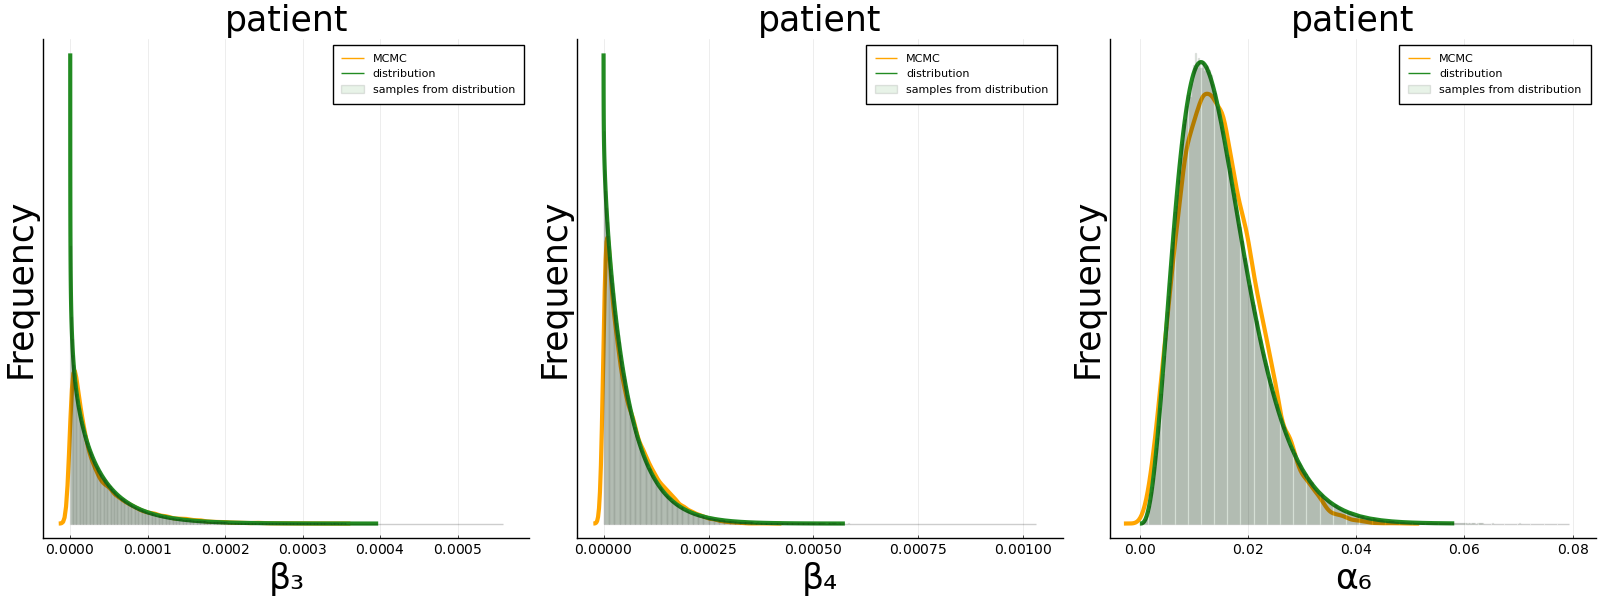

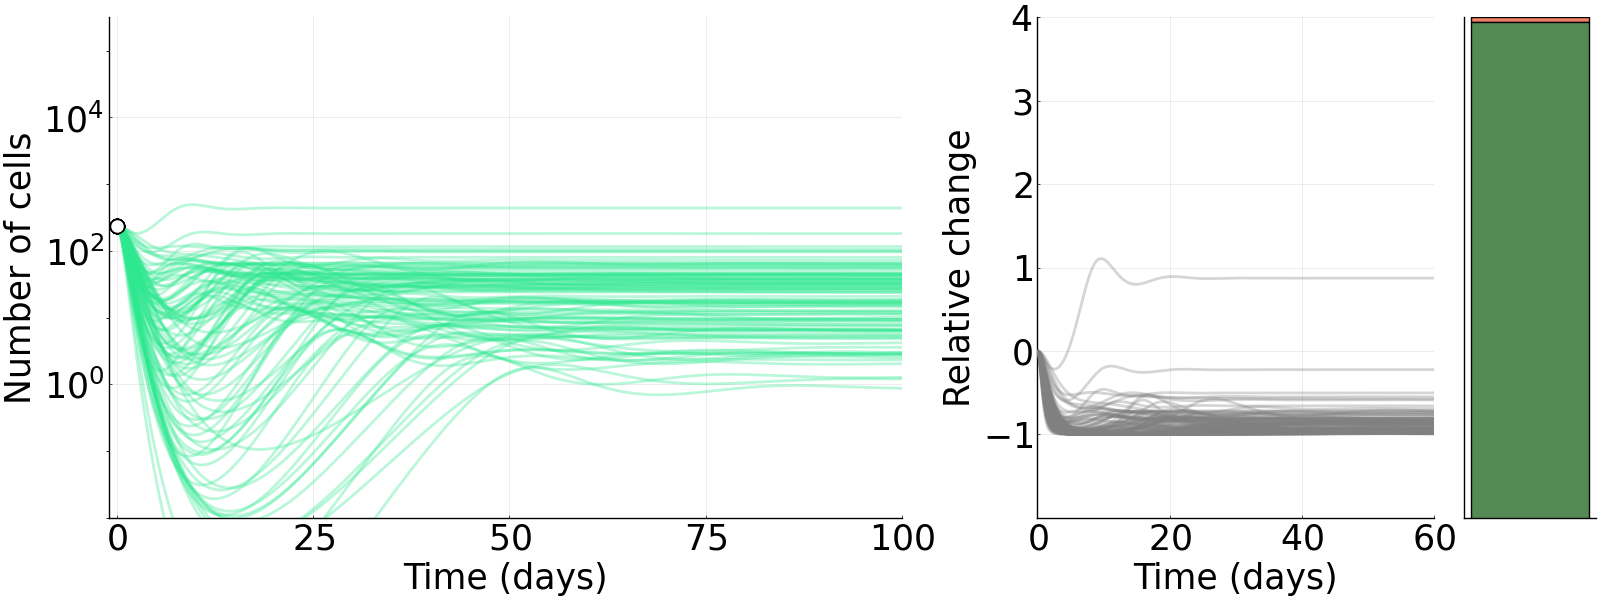

13
-0.873416939


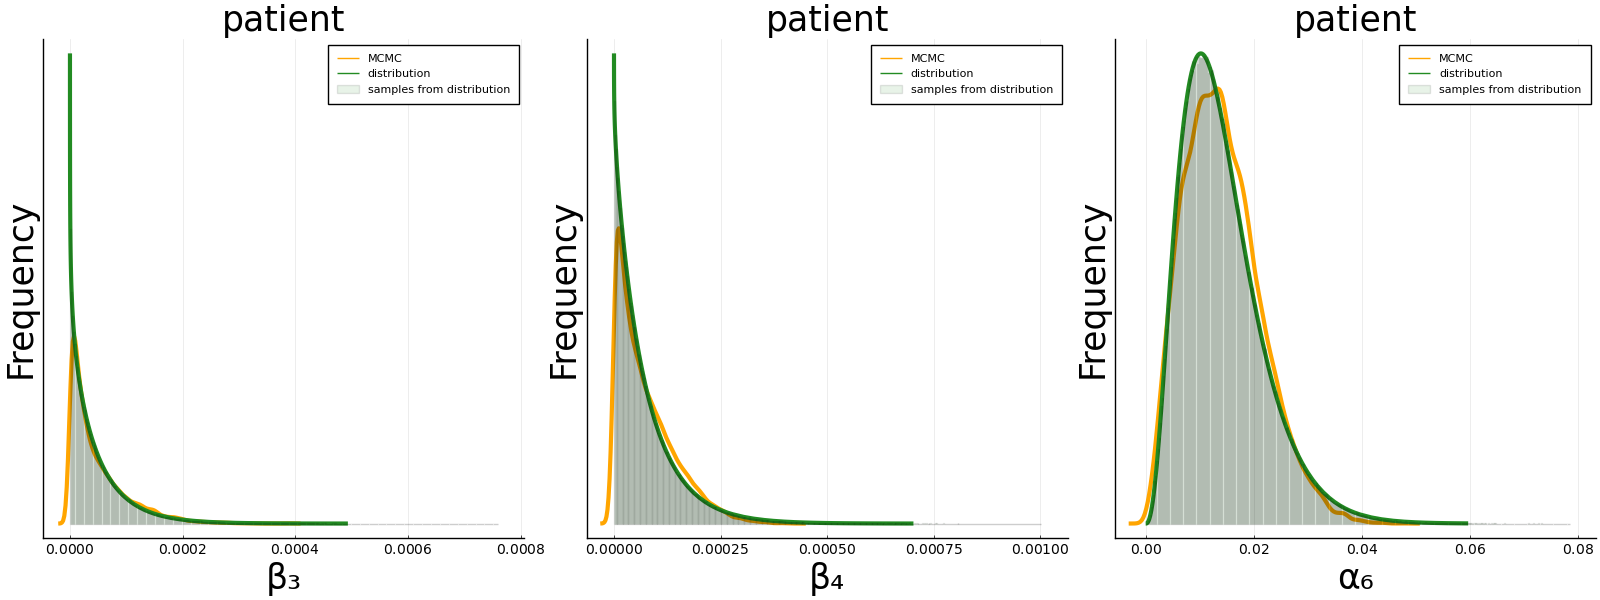

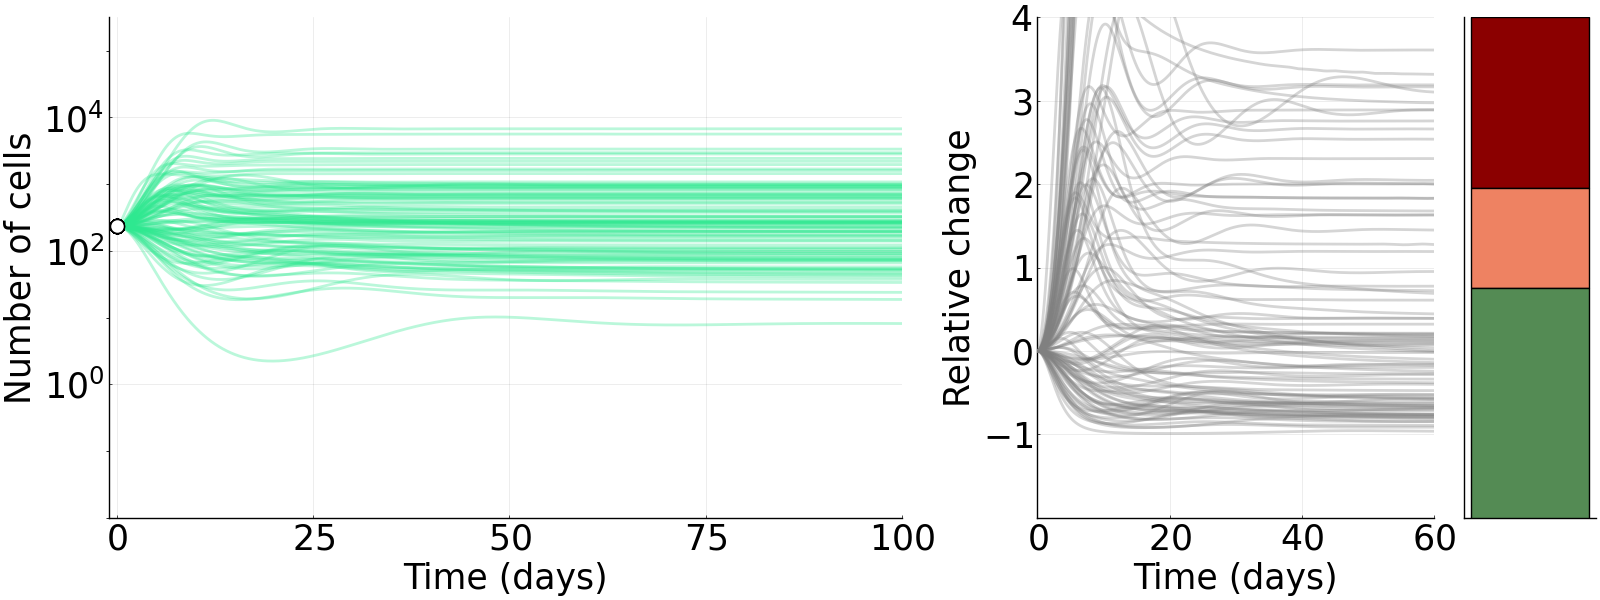

15
-0.750295424


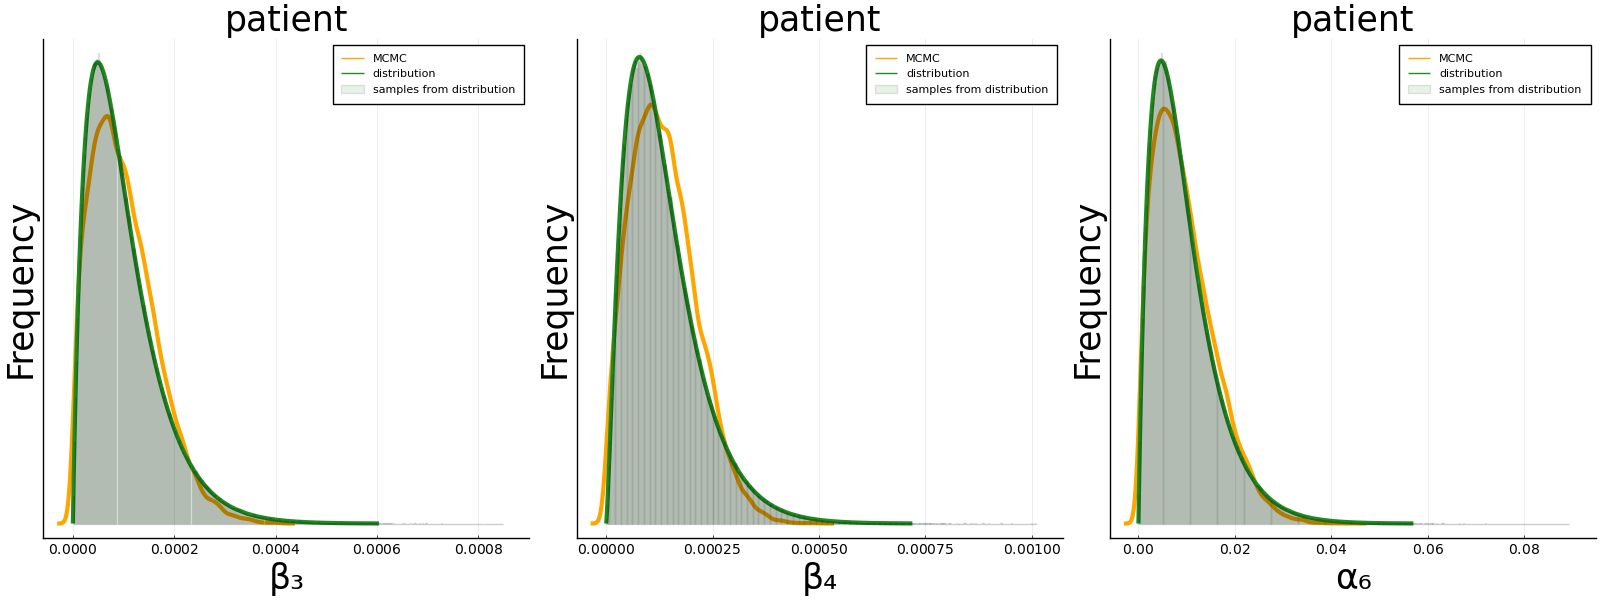

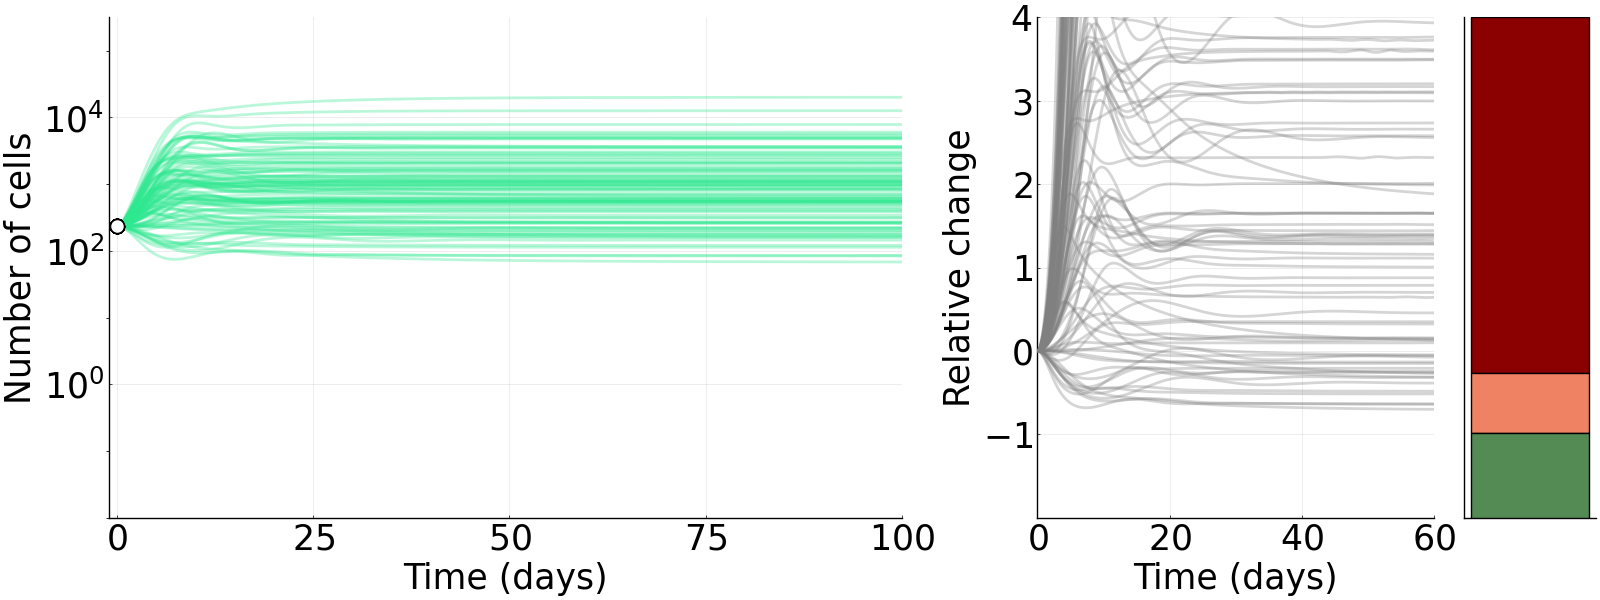

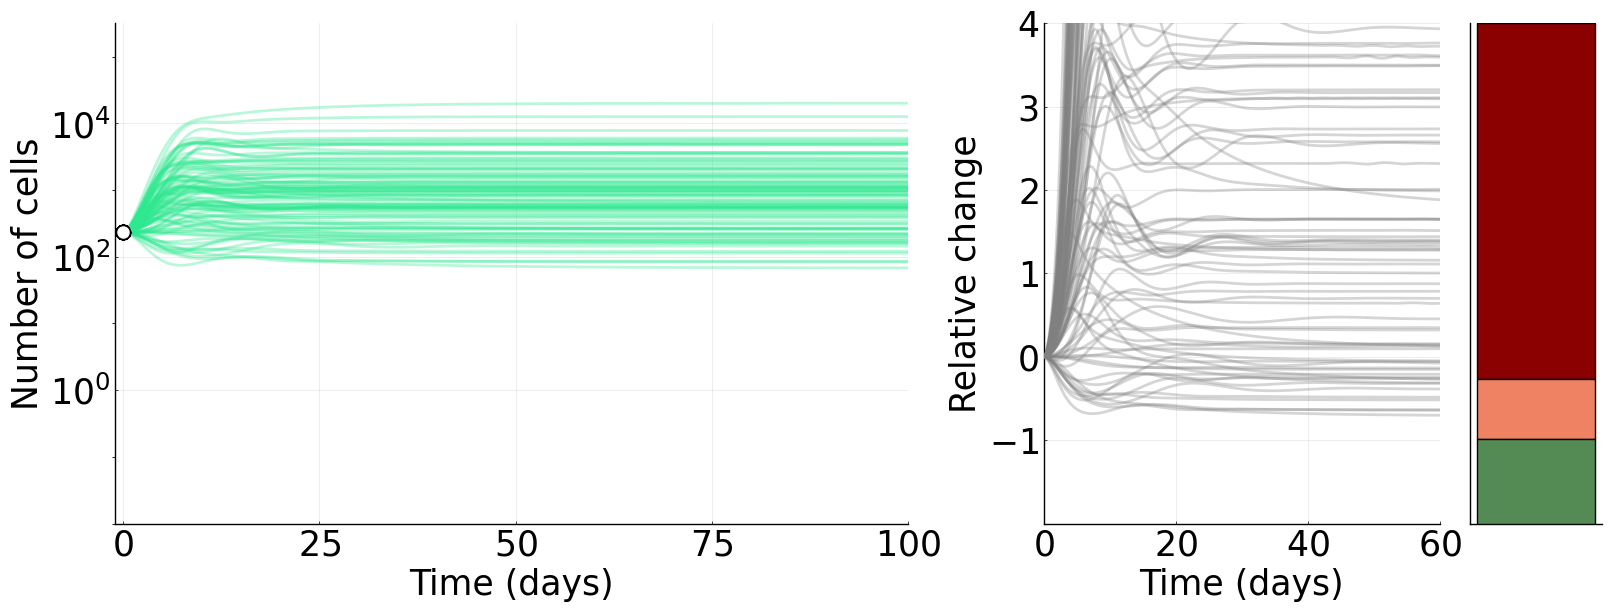

In [164]:
#plot fitted distributions and virtual tumors for patients with α₆ boost
stats = zeros(3)

alpha_six_boost = 0.0

for patient_number ∈ [1,13,15]
    
    stats = zeros(3)
    
    if patient_number == 1
        alpha_six_boost = IMC_array[1,3]
    elseif patient_number == 13
        alpha_six_boost = IMC_array[2,3]
    elseif patient_number == 15
        alpha_six_boost = IMC_array[3,3]
    else 
        alpha_six_boost = 0.0
    end
    
    println(patient_number)
    println(alpha_six_boost)

    chain_data_patient_classification = big_chain[:,:,patient_classification[patient_number,1]:patient_classification[patient_number,2]]

    chain_data_patient_classification2 = zeros((patient_classification[patient_number,2] - patient_classification[patient_number,1] + 1)*8000,4)
    for i = 1:(patient_classification[patient_number,2] - patient_classification[patient_number,1] + 1)
        chain_data_patient_classification2[(i-1)*8000+1:i*8000,:] = chain_data_patient_classification[:,:,i]
    end

    number_of_sims = 100
    sol_tumor = zeros(number_of_sims,Int(tspan[2]).*10+1)
    new_sol_full = zeros(number_of_sims,Int(tspan[2]).*10+1)

    
    plot()
    patient_dist1 = fit(Gamma, chain_data_patient_classification2[:,1])
    patient_sample1 = rand(Truncated(patient_dist1,0.0,1.0),1000000)
    density!(chain_data_patient_classification2[:,1], label = "MCMC", color = "orange", width = 3)
    plot!(patient_dist1, label = "distribution", color = "forestgreen", width = 3)
    patient_distplot1 = histogram!(patient_sample1, label = "samples from distribution", color = "forestgreen", alpha = 0.1, normalize=:pdf, xlabel="β₃")

    plot()
    patient_dist2 = fit(Gamma, chain_data_patient_classification2[:,2])
    patient_sample2 = rand(Truncated(patient_dist2,0.0,1.0),1000000)
    density!(chain_data_patient_classification2[:,2], label = "MCMC", color = "orange", width = 3)
    plot!(patient_dist2, label = "distribution", color = "forestgreen", width = 3)
    patient_distplot2 = histogram!(patient_sample2, label = "samples from distribution", color = "forestgreen", alpha = 0.1, normalize=:pdf, xlabel="β₄")

    plot()
    patient_dist3 = fit(Gamma, chain_data_patient_classification2[:,3])
    patient_sample3 = rand(Truncated(patient_dist3,0.0,1.0),1000000)
    density!(chain_data_patient_classification2[:,3], label = "MCMC", color = "orange", width = 3)
    plot!(patient_dist3, label = "distribution", color = "forestgreen", width = 3)
    patient_distplot3 = histogram!(patient_sample3, label = "samples from distribution", color = "forestgreen", alpha = 0.1, normalize=:pdf, xlabel="α₆")

    display(plot(patient_distplot1, patient_distplot2, patient_distplot3, layout = grid(1,3), size = (1600,600), title = "patient", font = "Ariel", yticks = :none, xtickfontsize=10, ytickfontsize=25, xguidefontsize=25, ylabel="Frequency", yguidefontsize=25, titlefontsize=25))
    

    p_rand = zeros(3)

    for j = 1:number_of_sims


        p_rand = zeros(3)
        p_rand[1] = rand(Truncated(patient_dist1,0.0,1.0))
        p_rand[2] = rand(Truncated(patient_dist2,0.0,1.0))
        p_rand[3] = rand(Truncated(patient_dist3,0.0,1.0)) .* (1 + alpha_six_boost)


        prob1 = ODEProblem(ode_system,u0,tspan,p_rand)
        sol = solve(prob1,alg,saveat=0.1,callback=floor_event)

        for k = 1:Int(tspan[2]).*10+1
            sol_tumor[j,k] = sol.u[k][1]
        end


        new_sol = zeros(Int(tspan[2]).*10+1)
        new_sol[1] = 0
        for i = 2:Int(tspan[2]).*10+1
            new_sol[i] = (sol.u[i][1]-u0[1])./u0[1]
        end

        for k = 1:Int(tspan[2]).*10+1
            new_sol_full[j,k] = new_sol[k]
        end
        
        if last(new_sol_full[j,:]) < 0
            stats[1] = stats[1] + 1
        elseif last(new_sol_full[j,:]) < 1
            stats[2] = stats[2] + 1
        else
            stats[3] = stats[3] + 1
        end
    end
    
    stats = stats./number_of_sims
    
    plot()
    for j = 1:number_of_sims
        plot!(sol.t, sol_tumor[j,:], lw = 2, style = :solid, yaxis=:log,size =(1600/2,600), font = "Ariel", ylims = (0.01,10^5.5), color = [color10 "darkblue" color_vector_patient[patient_number]], alpha = 0.33, legend = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Number of cells",yguidefontsize=25,title = "",titlefontsize=25)
        scatter!((0, u0[1]), color = "white", markersize = 10, xlims = [0,100])
    end
    a = plot!(xlims = [-1,100], yticks = [1,100,10000])

    plot()
    for j = 1:number_of_sims
        plot!(sol.t, new_sol_full[j,:], lw = 2, style = :solid, color = "gray", alpha = 0.33, size =(1600/2,600), font = "Ariel", xlims = (-5,tspan[2]+5), ylims = (-2,4), legend = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Relative change",yguidefontsize=25,title = "",titlefontsize=25)
    end
    b = plot!(xlims = [0,60], xticks = (0:20:60), yticks = (-1:1:4))
    
    plot()
    d = groupedbar(reverse(transpose(stats)), bar_position = :stack, size =(1600/2,600), font = "Ariel", palette = reverse(["palegreen4", "salmon2", "red4"]), legend = false, xticks = (1:1,[""]), yticks = :none, ylims = (0,1), xtickfontsize=25,ytickfontsize=25,xlabel="",xguidefontsize=25,ylabel="",yguidefontsize=25,title = "",titlefontsize=25)

    figure_plot = plot(a, b, d, layout = grid(1,3, widths=[0.6, 0.3, 0.1]), size = (1600,600))
    display(figure_plot)
    
    
    #plot joint posterior
    scatter()
    label_one =[]
    label_two = []

    for j = 1:number_of_parameters
        for k = 1:number_of_parameters
            for i = 1:(patient_classification[patient_number,2] - patient_classification[patient_number,1] + 1)
                label_one = parameters_symbols[j]
                label_two = parameters_symbols[k]
                scatter!(chain_data_patient_classification[:,j,i], chain_data_patient_classification[:,k,i], markercolor = color_vector_patient[patient_number], markerstrokewidth = 0, markeralpha = 0.05, xlab = "$label_one", ylab = "$label_two", legend = :false, size = (1600/3,600), font = "Ariel", xtickfontsize=12,ytickfontsize=12,xguidefontsize=25,yguidefontsize=25,titlefontsize=25)
            end
        plot()
        end
    end
    
    scatter()
    label_one =[]
    label_two = []

    for j = 1:number_of_parameters
        k = j
        for i = 1:(patient_classification[patient_number,2] - patient_classification[patient_number,1] + 1)
            label_one = parameters_symbols[j]
            label_two = parameters_symbols[k]
            density!(chain_data_patient_classification[:,j,i],  color = color_vector_patient[patient_number], markerstrokewidth = 0, markeralpha = 0.05, xlab = "$label_one", ylab = "$label_two", legend = :false, size = (1600/3,600), font = "Ariel", xtickfontsize=12,ytickfontsize=12,xguidefontsize=25,yguidefontsize=25,titlefontsize=25)
        end
        plot()
    end
end